In [1]:
import pandas as pd
import numpy as np
import  matplotlib.pyplot as plt
import glob
import os
import cmath 
import json
import seaborn as sns
from collections import Counter
from scipy.stats import linregress


QUESTIONS A POSER : 
- pourquoi le temps de réaction est parfois négatif ? 

In [39]:
data = pd.read_csv("données MEG/FRINT_MEG_S0.csv", index_col = 0)
data

,rotangle_1,rotangle_2,rotangle_3,rotangle_4,rotangle_5,rotangle_6,rotangle_7,presangle_1,presangle_2,presangle_3,...,rotations_6,rotations_7,target,presavg,optimal,GenMean,Block,Seqlen,final_angle,trial_rt
Var1,,,,,,,,,,,,,,,,,,,,,
0,28.822982,NaN,NaN,NaN,NaN,NaN,NaN,73.822982,NaN,NaN,...,NaN,NaN,28.822982,73.822982,28.822982,27.553769,1,1,29.948780,29.948780
1,117.783048,NaN,NaN,NaN,NaN,NaN,NaN,162.783048,NaN,NaN,...,NaN,NaN,117.783048,162.783048,117.783048,102.377246,1,1,-60.018361,-60.018361
2,3.878374,NaN,NaN,NaN,NaN,NaN,NaN,48.878374,NaN,NaN,...,NaN,NaN,3.878374,48.878374,3.878374,25.894652,1,1,-19.506362,-19.506362
3,67.664622,44.558261,40.703065,41.279455,96.268848,NaN,NaN,67.664622,44.558261,-4.296935,...,NaN,NaN,55.946871,51.688477,55.946871,60.629477,1,5,56.511500,56.511500
4,155.963133,113.323988,110.579157,NaN,NaN,NaN,NaN,110.963133,68.323988,155.579157,...,NaN,NaN,125.045190,111.049514,125.045190,115.649086,1,3,90.000000,90.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
315,104.544226,134.668057,70.463406,131.992886,78.787048,NaN,NaN,149.544226,89.668057,115.463406,...,NaN,NaN,104.313413,129.370606,104.313413,99.759580,10,5,127.226717,127.226717
316,72.535569,91.439420,113.953749,NaN,NaN,NaN,NaN,27.535569,136.439420,158.953749,...,NaN,NaN,92.522564,164.055118,92.522564,81.068330,10,3,117.897271,117.897271
317,86.735710,88.671335,52.006199,70.213803,109.530776,96.639391,73.825672,86.735710,133.671335,52.006199,...,-45.0,-45.0,82.777138,113.121510,82.777138,91.136763,10,7,177.053553,177.053553


## Fonctions

In [3]:
def CircularMean(a):
    if len(a)==0:
        return(np.nan)
    resulting_vector = 0
    for i in range(len(a)):
        if not  np.isnan(a[i]):
            resulting_vector+= cmath.exp(complex(0, 2*a[i]))
    return((np.angle(resulting_vector))/2)

In [4]:
def circular_error(a, b):
    return ((a - b + np.pi/2) % np.pi) - np.pi/2   # équivalent de [-90°, +90°]

def circular_error_deg(a, b):
    return ((a - b + 180/2) % 180) - 180/2   # équivalent de [-90°, +90°]

In [5]:
# norme du vecteur moyen circulaire pour des orientations. Retourne une valeur entre 0 et 1
# Proche de 1 = angles très proches, proche de 0 = angles très dispersés

def confiance (angle_list_rad) :
    if len(angle_list_rad)==0:
        return(np.nan)
    doubled = 2*angle_list_rad
    resultant = 0 
    for theta in doubled:
        if not np.isnan(theta):
            resultant += cmath.exp(complex(0, theta))
    return abs(resultant) / len(angle_list_rad)

## Filtering du dataframe pour 1 sujet

### dataframe en degré

In [40]:
data.columns = data.columns.str.strip()
data

,rotangle_1,rotangle_2,rotangle_3,rotangle_4,rotangle_5,rotangle_6,rotangle_7,presangle_1,presangle_2,presangle_3,...,rotations_6,rotations_7,target,presavg,optimal,GenMean,Block,Seqlen,final_angle,trial_rt
Var1,,,,,,,,,,,,,,,,,,,,,
0,28.822982,NaN,NaN,NaN,NaN,NaN,NaN,73.822982,NaN,NaN,...,NaN,NaN,28.822982,73.822982,28.822982,27.553769,1,1,29.948780,29.948780
1,117.783048,NaN,NaN,NaN,NaN,NaN,NaN,162.783048,NaN,NaN,...,NaN,NaN,117.783048,162.783048,117.783048,102.377246,1,1,-60.018361,-60.018361
2,3.878374,NaN,NaN,NaN,NaN,NaN,NaN,48.878374,NaN,NaN,...,NaN,NaN,3.878374,48.878374,3.878374,25.894652,1,1,-19.506362,-19.506362
3,67.664622,44.558261,40.703065,41.279455,96.268848,NaN,NaN,67.664622,44.558261,-4.296935,...,NaN,NaN,55.946871,51.688477,55.946871,60.629477,1,5,56.511500,56.511500
4,155.963133,113.323988,110.579157,NaN,NaN,NaN,NaN,110.963133,68.323988,155.579157,...,NaN,NaN,125.045190,111.049514,125.045190,115.649086,1,3,90.000000,90.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
315,104.544226,134.668057,70.463406,131.992886,78.787048,NaN,NaN,149.544226,89.668057,115.463406,...,NaN,NaN,104.313413,129.370606,104.313413,99.759580,10,5,127.226717,127.226717
316,72.535569,91.439420,113.953749,NaN,NaN,NaN,NaN,27.535569,136.439420,158.953749,...,NaN,NaN,92.522564,164.055118,92.522564,81.068330,10,3,117.897271,117.897271
317,86.735710,88.671335,52.006199,70.213803,109.530776,96.639391,73.825672,86.735710,133.671335,52.006199,...,-45.0,-45.0,82.777138,113.121510,82.777138,91.136763,10,7,177.053553,177.053553


In [41]:
df_filtered = data.copy()
# Exemple: sélection des colonnes rotangle_1 à rotangle_7
rotangle_cols = [f'rotangle_{i}' for i in range(1, 8)]
rotation_cols = [f'rotations_{i}' for i in range(1, 8)]
presangle_cols = [f'presangle_{i}' for i in range(1, 8)]

df_filtered['presented_angles'] = df_filtered[presangle_cols].apply(lambda row: row.dropna().tolist(), axis=1)
df_filtered['expected_angles'] = df_filtered[rotangle_cols].apply(lambda row: row.dropna().tolist(), axis=1)
df_filtered['stimulus_rotations'] = df_filtered[rotation_cols].apply(lambda row: row.dropna().tolist(), axis=1)
df_filtered["expected_angles_wo_rot"] = df_filtered["presavg"]
df_filtered["length of sequence"] = df_filtered["Seqlen"]

df_filtered = df_filtered.drop(columns=rotangle_cols + rotation_cols + presangle_cols)

df_filtered = df_filtered.drop(columns=["optimal", "presavg", "Seqlen"])
df_filtered.reset_index(drop=True, inplace=True)
df_filtered = df_filtered.dropna(subset=["final_angle"])
df_filtered


,target,GenMean,Block,final_angle,trial_rt,presented_angles,expected_angles,stimulus_rotations,expected_angles_wo_rot,length of sequence
0,28.822982,27.553769,1,29.948780,29.948780,[73.8229819],[28.8229819],[-45.0],73.822982,1
1,117.783048,102.377246,1,-60.018361,-60.018361,[162.783048],[117.783048],[-45.0],162.783048,1
2,3.878374,25.894652,1,-19.506362,-19.506362,[48.87837369],[3.87837369],[-45.0],48.878374,1
3,55.946871,60.629477,1,56.511500,56.511500,"[67.66462224, 44.55826071, -4.29693461, 41.279...","[67.66462224, 44.55826071, 40.70306539, 41.279...","[0.0, 0.0, 45.0, 0.0, 0.0]",51.688477,5
4,125.045190,115.649086,1,90.000000,90.000000,"[110.96313306, 68.32398801, 155.57915684]","[155.96313306, 113.32398801, 110.57915684]","[45.0, 45.0, -45.0]",111.049514,3
...,...,...,...,...,...,...,...,...,...,...
315,104.313413,99.759580,10,127.226717,127.226717,"[149.54422552, 89.66805657, 115.46340557, 176....","[104.54422552, 134.66805657, 70.46340557, 131....","[-45.0, 45.0, -45.0, -45.0, -45.0]",129.370606,5
316,92.522564,81.068330,10,117.897271,117.897271,"[27.5355694, 136.43942041, 158.95374922]","[72.5355694, 91.43942041, 113.95374922]","[45.0, -45.0, -45.0]",164.055118,3
317,82.777138,91.136763,10,177.053553,177.053553,"[86.73570974, 133.67133526, 52.00619852, 115.2...","[86.73570974, 88.67133526, 52.00619852, 70.213...","[0.0, -45.0, 0.0, -45.0, 0.0, -45.0, -45.0]",113.121510,7
318,178.047458,172.978580,10,-151.774666,-151.774666,"[166.39795639, 188.26821281, 159.6790459, 120....","[166.39795639, 188.26821281, 159.6790459, 165....","[0.0, 0.0, 0.0, 45.0, 0.0, 45.0, 45.0]",158.028529,7


In [42]:
df_radian = df_filtered.copy().drop(columns=["presented_angles", "final_angle", "expected_angles", "stimulus_rotations", "GenMean", "target", "expected_angles_wo_rot"])
df_radian['final_angle'] = np.deg2rad(df_filtered['final_angle'])
df_radian["target"] = np.deg2rad(df_filtered['target'])
df_radian["GenMean"] = np.deg2rad(df_filtered['GenMean'])
df_radian["expected_angles_wo_rot"] = np.deg2rad(df_filtered['expected_angles_wo_rot'])

df_radian['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(
    lambda lst: np.deg2rad(np.array(lst, dtype=float)))

df_radian['presented_angles'] = df_filtered['presented_angles'].apply(
    lambda lst: np.deg2rad(np.array(lst, dtype=float)))

df_radian['expected_angles'] = df_filtered['expected_angles'].apply(
    lambda lst: np.deg2rad(np.array(lst, dtype=float)))


df_radian["mean_rotation"] = df_radian["stimulus_rotations"].apply(np.mean) 

df_radian

,Block,trial_rt,length of sequence,final_angle,target,GenMean,expected_angles_wo_rot,stimulus_rotations,presented_angles,expected_angles,mean_rotation
0,1,29.948780,1,0.522705,0.503056,0.480904,1.288454,[-0.7853981633974483],[1.2884540977951793],[0.503055934397731],-0.785398
1,1,-60.018361,1,-1.047518,2.055702,1.786820,2.841100,[-0.7853981633974483],[2.8411001540319707],[2.055701990634522],-0.785398
2,1,-19.506362,1,-0.340450,0.067690,0.451947,0.853089,[-0.7853981633974483],[0.8530885539106701],[0.06769039051322188],-0.785398
3,1,56.511500,5,0.986312,0.976457,1.058184,0.902134,"[0.0, 0.0, 0.7853981633974483, 0.0, 0.0]","[1.1809704452061807, 0.7776883583515262, -0.07...","[1.1809704452061807, 0.7776883583515262, 0.710...",0.157080
4,1,90.000000,3,1.570796,2.182450,2.018457,1.938180,"[0.7853981633974483, 0.7853981633974483, -0.78...","[1.9366720202255707, 1.1924785488676284, 2.715...","[2.7220701836230186, 1.9778767122650767, 1.929...",0.261799
...,...,...,...,...,...,...,...,...,...,...,...
315,10,127.226717,5,2.220525,1.820613,1.741133,2.257943,"[-0.7853981633974483, 0.7853981633974483, -0.7...","[2.6100391126689293, 1.5650028210110334, 2.015...","[1.824640949271481, 2.3504009844084814, 1.2298...",-0.471239
316,10,117.897271,3,2.057696,1.614823,1.414909,2.863302,"[0.7853981633974483, -0.7853981633974483, -0.7...","[0.4805863474413995, 2.3813171156672515, 2.774...","[1.2659845108388479, 1.5959189522698032, 1.988...",-0.261799
317,10,177.053553,7,3.090167,1.444734,1.590637,1.974343,"[0.0, -0.7853981633974483, 0.0, -0.78539816339...","[1.513823714017115, 2.3330049158241906, 0.9076...","[1.513823714017115, 1.5476067524267423, 0.9076...",-0.448799
318,10,-151.774666,7,-2.648968,3.107514,3.019046,2.758118,"[0.0, 0.0, 0.0, 0.7853981633974483, 0.0, 0.785...","[2.9041922075954374, 3.2859001903798655, 2.786...","[2.9041922075954374, 3.2859001903798655, 2.786...",0.336599


### dataframes pour tous les participants

In [ ]:
# filepaths = glob.glob("données MEG/*.csv")
# dfs = [pd.read_csv(f, index_col = 0) for f in filepaths]

# def all_participants (dfs) :
#     # delete useless columns and rows
#     df_radian = dfs[dfs["stimulus_rotations"].notna()]
#     df_radian = df_radian.drop(columns=["rt", "url", "target", "time_elapsed", "internal_node_id", "success", "responses", "view_history", "response_rts", "key_press", "confidence", "correct", "trial_type", "stimulus"])
#     df_radian.reset_index(drop=True, inplace=True)
#     df_radian["length of sequence"] = df_radian["presented_angles"].apply(lambda s: len(s.split(',')) if isinstance(s, str) else 0)
    
#     # everything in float/int
#     df_radian['presented_angles'] = df_radian['presented_angles'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
#     df_radian['stimulus_rotations'] = df_radian['stimulus_rotations'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
#     df_radian['score'] = df_radian['score'].astype(int)
    
#     # new columns 
#     df_radian["expected_angles"] = df_radian.apply(lambda row : [x + y for x,y in zip(row["presented_angles"],row["stimulus_rotations"])], axis=1)

#     # Apply radian conversion to every angles
#     df_radian['final_angle'] = df_radian['final_angle'].apply(np.deg2rad)
#     df_radian['presented_angles'] = df_radian['presented_angles'].apply(lambda lst: np.deg2rad(np.array(lst, dtype=float)))
#     df_radian['stimulus_rotations'] = df_radian['stimulus_rotations'].apply(lambda lst: np.deg2rad(np.array(lst, dtype=float)))    
#     df_radian['expected_angles'] = df_radian['expected_angles'].apply(lambda lst: np.deg2rad(np.array(lst, dtype=float)))    
    
#     df_radian["target"] = df_radian["expected_angles"].apply(CircularMean) # moyenne circulaire des angles attendus

#     df_radian["error_to_target"] = circular_error(df_radian["final_angle"], df_radian["target"]) # erreur par rapport à l'angle théorique
#     df_radian["dict_angle_to_rotation"]= df_radian.apply(lambda row: dict(zip(row["presented_angles"], row["stimulus_rotations"])), axis=1) 
#     df_radian["expected_angles_wo_rot"] = df_radian["presented_angles"].apply(CircularMean)
#     df_radian["error_wo_rotation"] = circular_error(df_radian["final_angle"], df_radian["expected_angles_wo_rot"])  
#     df_radian["mean_rotation"] = df_radian["stimulus_rotations"].apply(np.mean)
    

#     mean_rt = df_radian["trial_rt"].mean()
#     std_rt = df_radian["trial_rt"].std()
#     upper_threshold = mean_rt + 5*std_rt

#     rt_filtered = df_radian["trial_rt"].copy()
#     rt_filtered[(rt_filtered > upper_threshold)] = np.nan
#     df_radian["rt_filtered"] = rt_filtered
#     return df_radian

## Exploration métadatas

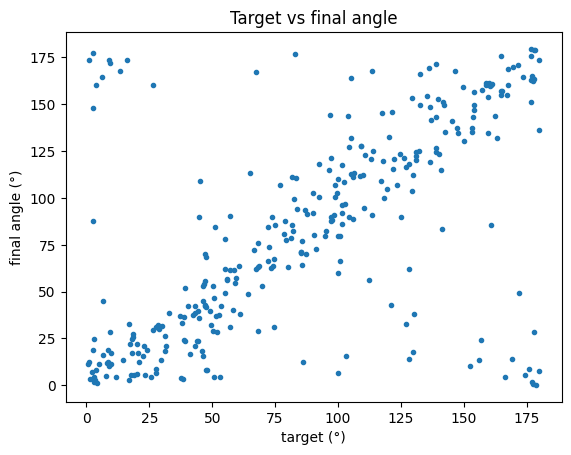

In [51]:
plt.plot(df_radian['target'].apply(np.rad2deg)%180, df_radian['final_angle'].apply(np.rad2deg)%180,".")
plt.xlabel("target (°)")
plt.ylabel("final angle (°)")
plt.title("Target vs final angle")
plt.show()

### infos sur les proportions de rotations

In [52]:
# Extraire toutes les listes de angles
angles_lists = df_filtered["stimulus_rotations"]

# 1. Trouver tous les angles uniques
all_angles = set()
for lst in angles_lists:
    all_angles.update(lst)

# 2. Proportion de listes contenant chaque angle
angle_presence = {}
total_lists = len(angles_lists)
for angle in all_angles:
    count = sum(angle in lst for lst in angles_lists)
    angle_presence[angle] = count / total_lists * 100  # en %

print("Proportion de listes contenant chaque angle (%) :")
for angle, pct in angle_presence.items():
    print(f"Angle {angle}: {pct:.1f}%")

# 3. Fréquence totale de chaque angle (toutes occurrences cumulées)
all_occurrences = [angle for lst in angles_lists for angle in lst]
freq = Counter(all_occurrences)

print("\nFréquence totale de chaque angle (nombre d'occurrences) :")
for angle, count in freq.items():
    print(f"Angle {angle}: {count}")

Proportion de listes contenant chaque angle (%) :
Angle 0.0: 67.5%
Angle -45.0: 67.8%
Angle 45.0: 68.8%

Fréquence totale de chaque angle (nombre d'occurrences) :
Angle -45.0: 428
Angle 0.0: 407
Angle 45.0: 445


In [53]:
# Création d'une colonne pour la longueur de chaque séquence
df_filtered['length_of_sequence'] = df_filtered['stimulus_rotations'].apply(len)

only_45 = df_filtered[df_filtered['stimulus_rotations'].apply(lambda x: all(angle == 45.0 for angle in x))]
only_minus45 = df_filtered[df_filtered['stimulus_rotations'].apply(lambda x: all(angle == -45.0 for angle in x))]

only_minus45_filtered = only_minus45[only_minus45['length_of_sequence'] > 1]
only_45_filtered = only_45[only_45['length_of_sequence'] > 1]

print("Séquences 100% de +45° et longueur > 1 :")
print("il y a ", len(only_45), "séquences 100% de +45° en tout, et", len(only_45_filtered),"séquences de 1 élément +45°")


print("\nSéquences 100% de -45° et longueur > 1 :")
print("il y a ", len(only_minus45), "séquences 100% de +45° en tout, et", len(only_minus45_filtered),"séquences de 1 élément -45°")



Séquences 100% de +45° et longueur > 1 :
il y a  30 séquences 100% de +45° en tout, et 3 séquences de 1 élément +45°

Séquences 100% de -45° et longueur > 1 :
il y a  30 séquences 100% de +45° en tout, et 3 séquences de 1 élément -45°


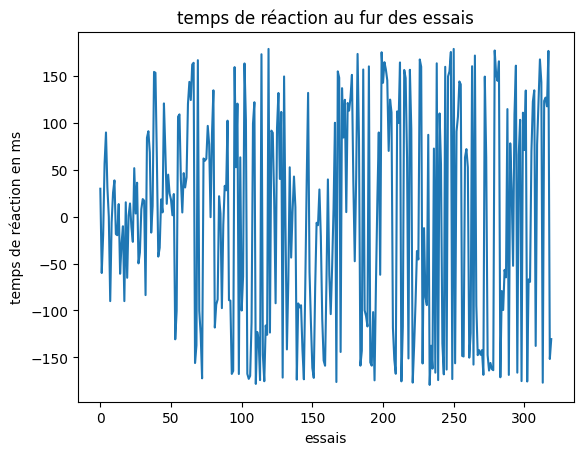

In [57]:
plt.plot(df_filtered["trial_rt"])
plt.title("temps de réaction au fur des essais")
plt.xlabel("essais")
plt.ylabel("temps de réaction en ms")
plt.show()

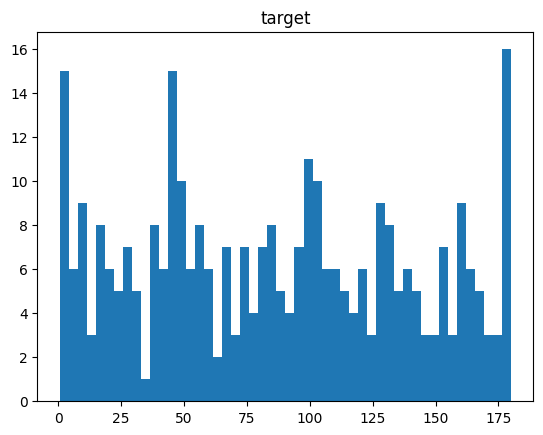

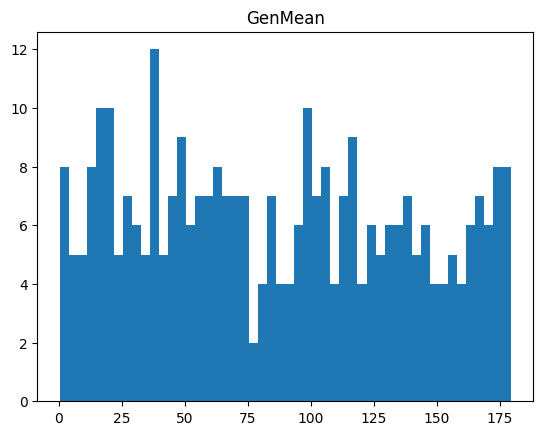

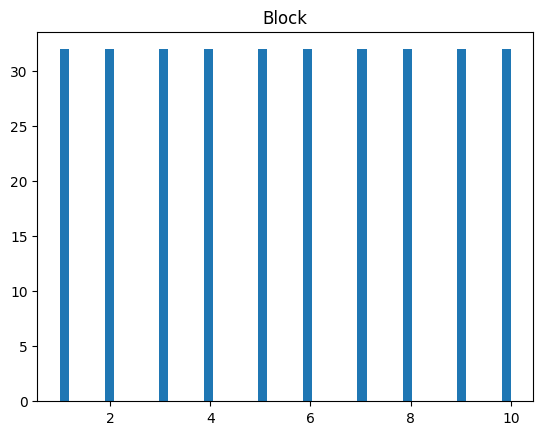

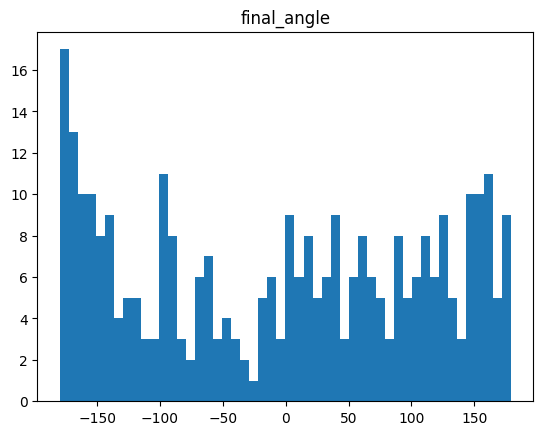

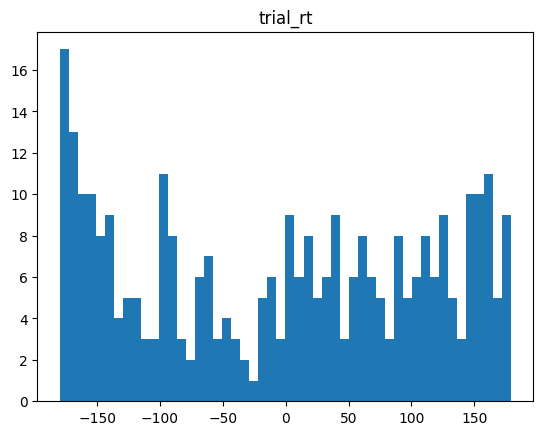

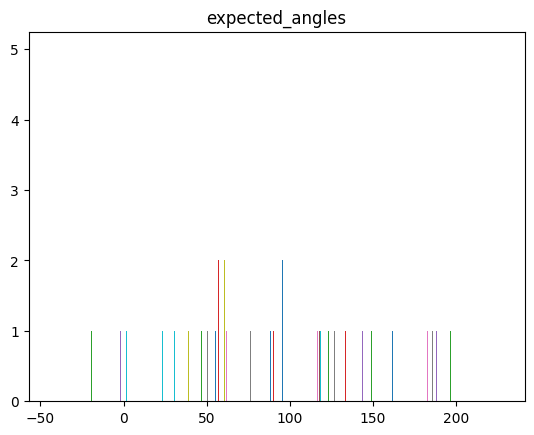

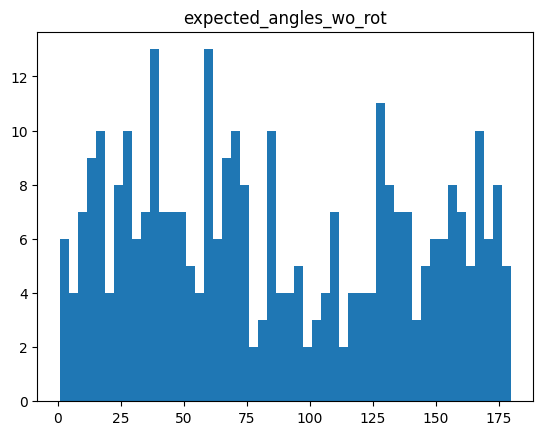

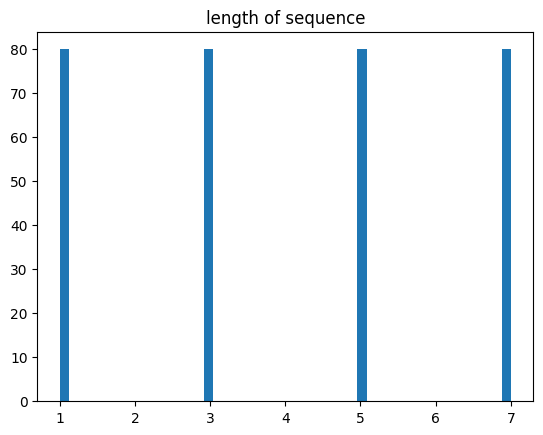

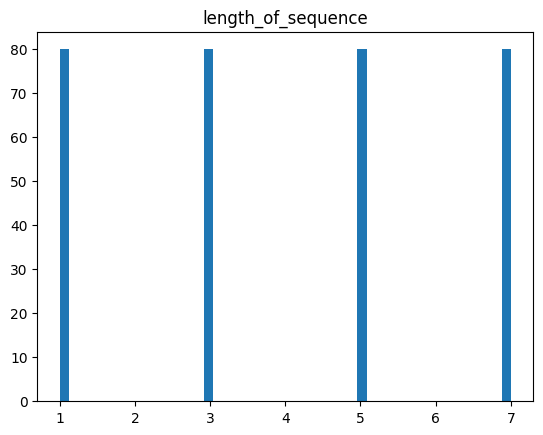

In [ ]:
for column in df_filtered.columns:
    if column not in ["presented_angles", "stimulus_rotations"]:
        plt.figure()
        plt.hist(df_filtered[column], bins=50)
        plt.title(column)
        plt.show()

### data sur tous les participants

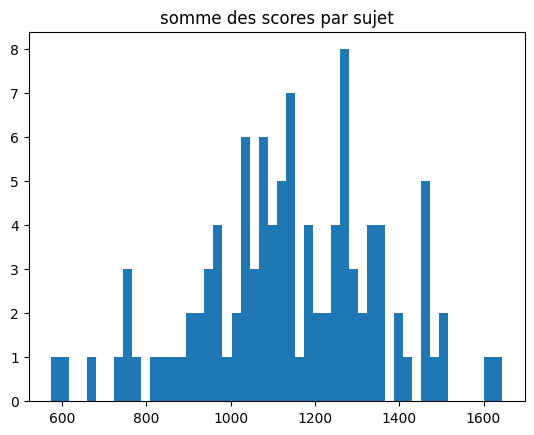

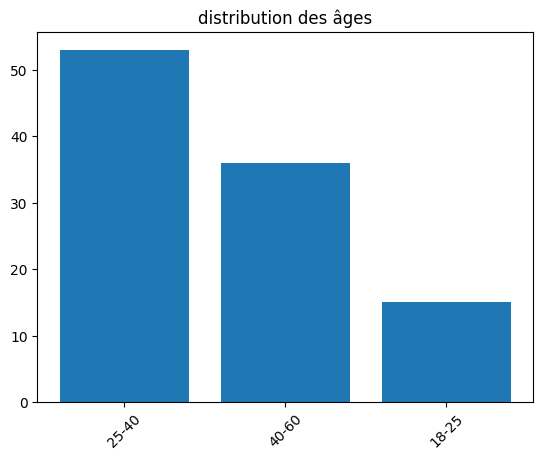

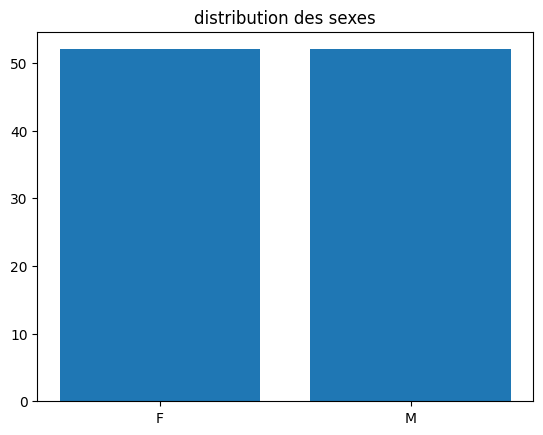

In [ ]:
filepaths = glob.glob("données/*.csv")
dfs = [pd.read_csv(f, skiprows=1, index_col=3) for f in filepaths]

def data_sujets (dfs) : 
    score_sum = []
    age_tot = []
    sexe_tot = []
    for df in dfs :    
        survey = df[df["trial_type"] == "survey-dropdown"]
        if len(survey) == 0:
            age, sexe = None, None
        else:
            resp = json.loads(survey.iloc[0]["responses"])
            age = resp.get("0")
            sexe = resp.get("1")        
        age_tot.append(age)
        sexe_tot.append(sexe)
        
        df_filtered = df[df["stimulus_rotations"].notna()].copy()
        df_filtered = df_filtered.dropna(subset=["final_angle"]).copy()
        
        df_filtered['score'] = pd.to_numeric(df_filtered["score"], errors="coerce")
        score_sum.append(df_filtered["score"].sum(skipna=True))
        
    return score_sum, age_tot, sexe_tot

scores, ages, sexes = data_sujets(dfs)

plt.hist(scores, bins=50)
plt.title("somme des scores par sujet")
# plt.savefig("/Users/elodiehusson/Desktop/Projet/Sanity check comportement code/somme des scores par sujet.pdf")
plt.show()

age_counts = pd.Series(ages).value_counts(dropna=False)
plt.bar(age_counts.index.astype(str), age_counts.values)
plt.xticks(rotation=45)
plt.title("distribution des âges")
# plt.savefig("/Users/elodiehusson/Desktop/Projet/Sanity check comportement code/distribution des ages.pdf")
plt.show()

sex_counts = pd.Series(sexes).value_counts(dropna=False)
plt.bar(sex_counts.index.astype(str), sex_counts.values)
plt.title("distribution des sexes")
# plt.savefig("/Users/elodiehusson/Desktop/Projet/Sanity check comportement code/distribution des sexes.pdf")
plt.show()

In [ ]:
print("il y a",sexes.count('F'), "femmes")
print("il y a",sexes.count('M'), 'hommes')
print("il y a",ages.count('18-25'), "personnes qui ont entre 18 et 25 ans")
print("il y a",ages.count('25-40'), 'personnes qui ont entre 25 et 40 ans')
print("il y a",ages.count('40-60'), 'personnes qui ont entre 40 et 60 ans')

il y a 52 femmes
il y a 52 hommes
il y a 15 personnes qui ont entre 18 et 25 ans
il y a 53 personnes qui ont entre 25 et 40 ans
il y a 36 personnes qui ont entre 40 et 60 ans


### Disposition des angles sur un cercle

ici je dois changer en mettant le cercle de -90° à 90°
ca c'est bizarre


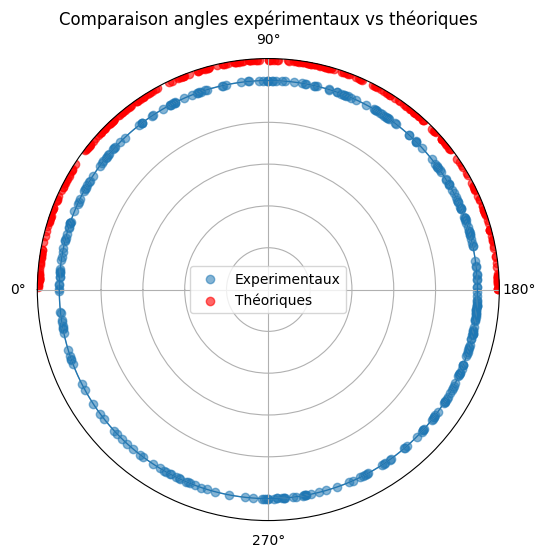

In [ ]:
fig = plt.figure(figsize=(6,6))
ax = plt.subplot(111, polar=True)

ax.set_theta_zero_location("W")   # 0° à gauche (comme ton choix)
ax.set_theta_direction(-1)        # sens horaire

# ---- CERCLE TRIGONOMÉTRIQUE ----
theta = np.linspace(0, 2*np.pi, 400)
ax.plot(theta, np.ones_like(theta), linewidth=1)  # cercle unité

# labels angulaires
ax.set_thetagrids(
    angles=[0, 90, 180, 270],
    labels=["0°", "90°", "180°", "270°"]
)

# ---- TES DONNÉES ----
theta_presented = df_radian['final_angle'].values
theta_targets = df_radian['target'].values

ax.scatter(theta_presented, np.ones_like(theta_presented),
           alpha=0.55, label="Experimentaux")

ax.scatter(theta_targets, np.ones_like(theta_targets)*1.1,
           color='red', alpha=0.6, label="Théoriques")

ax.set_yticklabels([])   # enlève les labels du rayon
ax.set_title("Comparaison angles expérimentaux vs théoriques")
ax.legend()

plt.show()

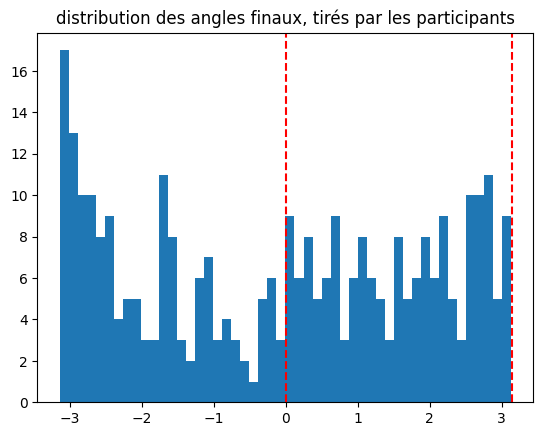

In [ ]:
plt.hist(df_radian["final_angle"], bins=50)
plt.axvline(0, color='red', linestyle='--')
plt.axvline(np.pi, color='red', linestyle='--')
plt.title("distribution des angles finaux, tirés par les participants")
plt.show()

## Performances

### Est ce que les participants ont bien répondu ? (erreur entre angle tiré et la target) 

+ ajouter la confiance pour voir la distribution de la confiance pour les angles expected 

In [ ]:
df_radian["error_to_target"] = circular_error(df_radian["final_angle"], df_radian["target"]) # erreur par rapport à l'angle théorique
df_filtered["error_to_target"] = circular_error_deg(df_filtered["final_angle"], df_filtered["target"]) # erreur par rapport à l'angle théorique

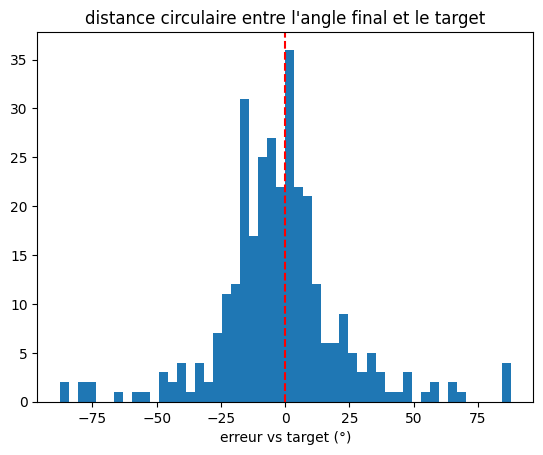

In [ ]:
plt.hist(np.rad2deg(df_radian["error_to_target"]), bins=50)
plt.axvline(0, color='red', linestyle='--') 
plt.xlabel("erreur vs target (°)")
plt.title("distance circulaire entre l'angle final et le target")
plt.show()

### Est ce que les participants ignorent les rotations ? (ne considèrent que les gris)

j'ai besoin de prendre toutes les presented angles, et de garder seulement les 0°, et de comparer leur moyenne circulaire avec l'angle final tiré


In [ ]:
df_radian["dict_angle_to_rotation"]= df_radian.apply(lambda row: dict(zip(row["presented_angles"], row["stimulus_rotations"])), axis=1) 

In [ ]:
df_radian["angles_sans_rotation"]= df_radian["dict_angle_to_rotation"].apply(lambda d: [angle for angle, rot in d.items() if np.isclose(rot, 0)])

df_radian_error_wo_rotation = df_radian[df_radian["angles_sans_rotation"].apply(len)>0]

df_radian_error_wo_rotation["error_sola_gris"] = circular_error(df_radian_error_wo_rotation["final_angle"], df_radian_error_wo_rotation["angles_sans_rotation"].apply(CircularMean))

/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_28693/2451352332.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_radian_error_wo_rotation["error_sola_gris"] = circular_error(df_radian_error_wo_rotation["final_angle"], df_radian_error_wo_rotation["angles_sans_rotation"].apply(CircularMean))


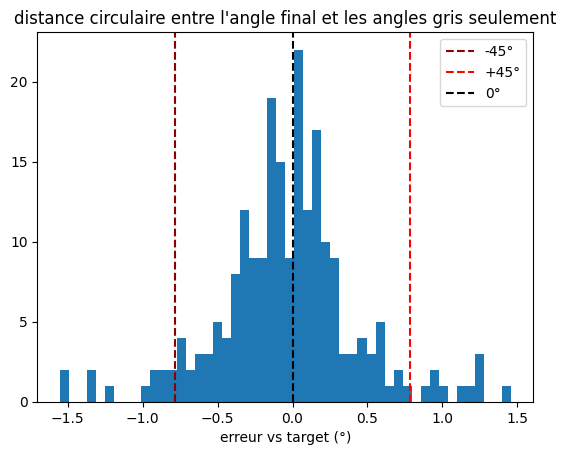

In [ ]:
plt.hist(df_radian_error_wo_rotation["error_sola_gris"], bins=50)
plt.axvline(np.deg2rad(-45), color='darkred', linestyle='--', label="-45°") 
plt.axvline(np.deg2rad(45), color='red', linestyle='--', label="+45°") 
plt.axvline(np.deg2rad(0), color='black', linestyle='--', label="0°") 

plt.xlabel("erreur vs target (°)")
plt.title("distance circulaire entre l'angle final et les angles gris seulement")
plt.legend()
plt.show()

### Est ce que les participants ignorent les rotations ? (ne prennent pas en compte les couleurs, seulement les orientations qu'ils voient)

In [ ]:
df_radian["expected_angles_wo_rot"] = df_radian["presented_angles"].apply(CircularMean)
df_radian["error_wo_rotation"] = circular_error(df_radian["final_angle"], df_radian["expected_angles_wo_rot"])  

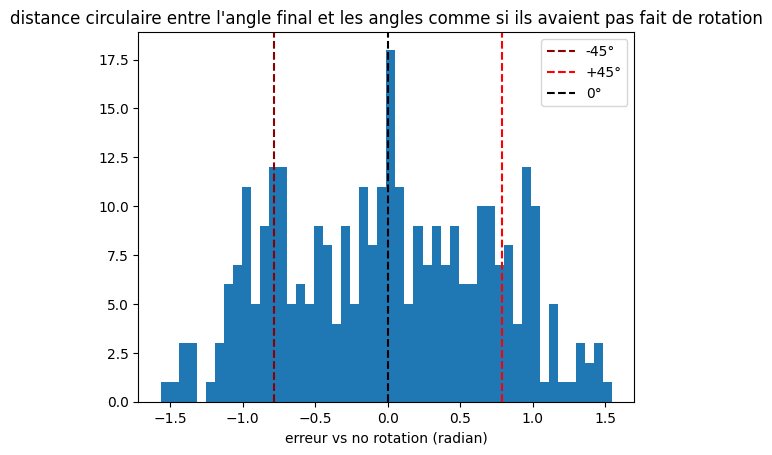

In [ ]:
plt.hist(df_radian["error_wo_rotation"], bins=50)
plt.axvline(np.deg2rad(-45), color='darkred', linestyle='--', label="-45°") 
plt.axvline(np.deg2rad(45), color='red', linestyle='--', label="+45°") 
plt.axvline(np.deg2rad(0), color='black', linestyle='--', label="0°") 

plt.xlabel("erreur vs no rotation (radian)")
plt.title("distance circulaire entre l'angle final et les angles comme si ils avaient pas fait de rotation")
plt.legend()
plt.show()

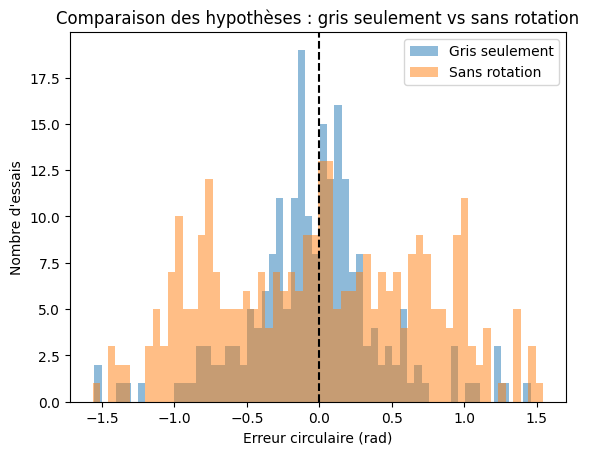

In [ ]:
plt.hist(df_radian_error_wo_rotation["error_sola_gris"], 
         bins=60, alpha=0.5, label="Gris seulement")

plt.hist(df_radian["error_wo_rotation"], 
         bins=60, alpha=0.5, label="Sans rotation")

plt.axvline(0, color="black", linestyle="--")
plt.xlabel("Erreur circulaire (rad)")
plt.ylabel("Nombre d'essais")
plt.title("Comparaison des hypothèses : gris seulement vs sans rotation")
plt.legend()
plt.show()

### rotation moyenne vs erreur

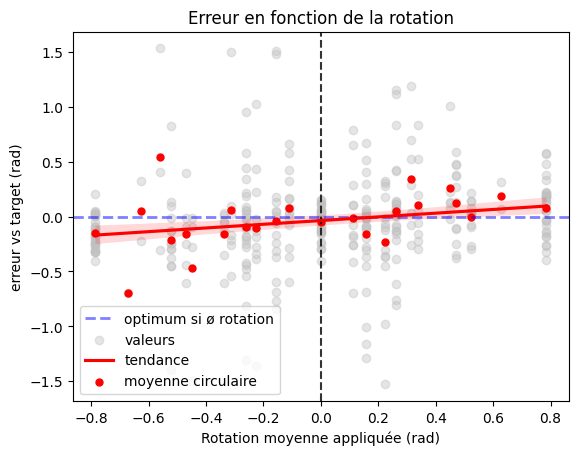

In [ ]:
x = (df_radian.groupby("mean_rotation")["error_to_target"].apply(np.mean).reset_index().sort_values("mean_rotation"))

plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
plt.axhline(0, color="blue", linestyle="--", label= "optimum si ø rotation", alpha = 0.5, linewidth =2)   

sns.regplot(x="mean_rotation", y="error_to_target", data=df_radian, color = "silver", label = "valeurs", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "tendance"})
plt.scatter(x["mean_rotation"], x["error_to_target"], color="red", s=25, label="moyenne circulaire")

plt.xlabel("Rotation moyenne appliquée (rad)")
plt.ylabel("erreur vs target (rad)")
plt.title("Erreur en fonction de la rotation")
plt.legend()
plt.show()

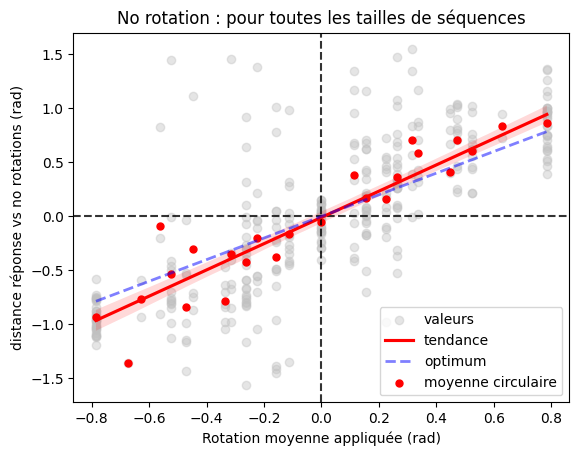

In [ ]:
x = (df_radian.groupby("mean_rotation")["error_wo_rotation"].apply(np.mean).reset_index().sort_values("mean_rotation"))


plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
plt.axhline(0, color="black", linestyle="--", alpha = 0.8)   

sns.regplot(x="mean_rotation", y="error_wo_rotation", data=df_radian, color = "silver", label = "valeurs", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "tendance"})
borne = x["mean_rotation"]
plt.plot(np.linspace(min(borne),max(borne),100),np.linspace(min(borne),max(borne),100),"--" , color = "blue",label= "optimum", alpha = 0.5, linewidth =2)
plt.scatter(x["mean_rotation"], x["error_wo_rotation"], color="red", s=25, label="moyenne circulaire")

plt.xlabel("Rotation moyenne appliquée (rad)")
plt.ylabel("distance réponse vs no rotations (rad)")
plt.title("No rotation : pour toutes les tailles de séquences")
plt.legend()
plt.show()

plot pour différentes tailles de séquences

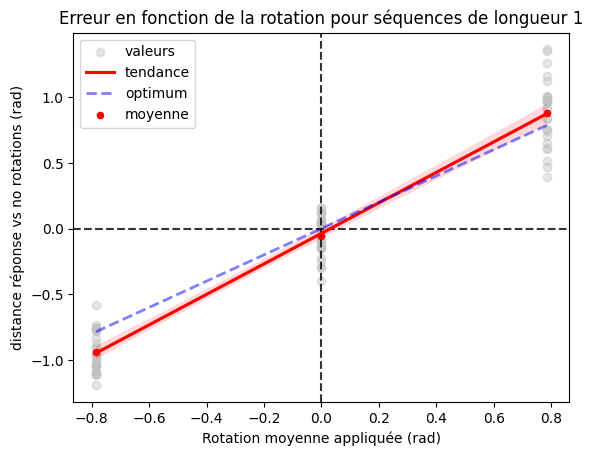

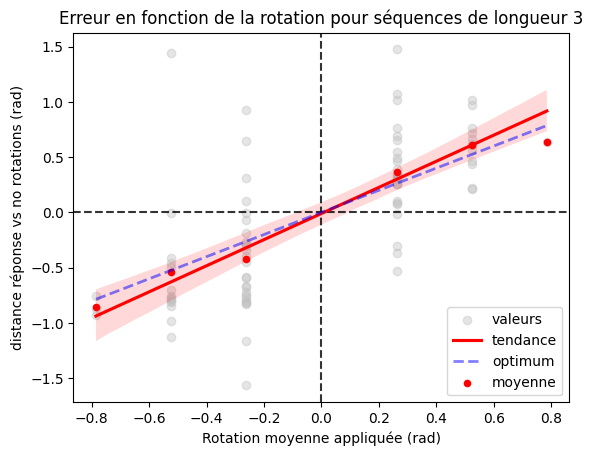

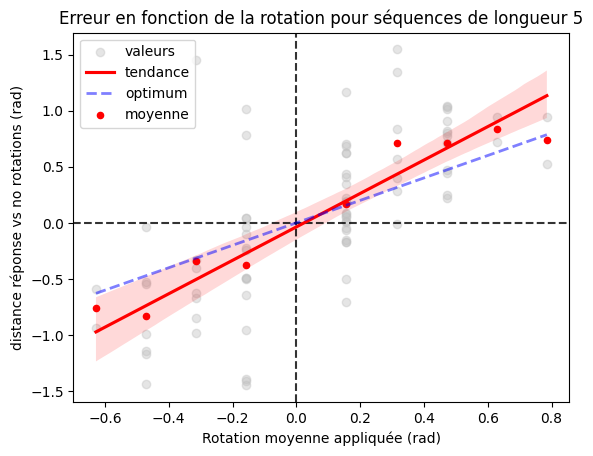

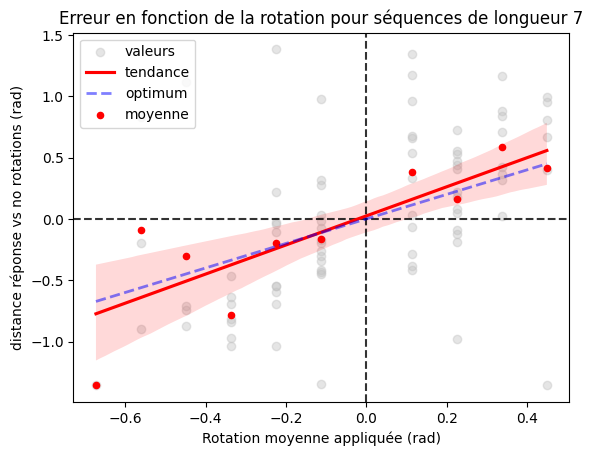

In [ ]:
for seqlen in [1,3,5,7] :
    plt.figure()
    x = (df_radian[df_radian["length of sequence"]==seqlen].groupby("mean_rotation")["error_wo_rotation"].apply(np.mean).reset_index().sort_values("mean_rotation"))

    plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
    plt.axhline(0, color="black", linestyle="--", alpha = 0.8)   

    borne = x["mean_rotation"]
    sns.regplot(x="mean_rotation", y="error_wo_rotation", data=df_radian[df_radian["length of sequence"]==seqlen], color = "silver", label = "valeurs", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "tendance"})
    plt.plot(np.linspace(min(borne),max(borne),100),np.linspace(min(borne),max(borne),100),"--" , color = "blue",label= "optimum", alpha = 0.5, linewidth =2)
    plt.scatter(x["mean_rotation"], x["error_wo_rotation"], color="red", s=20, label="moyenne")

    plt.xlabel("Rotation moyenne appliquée (rad)")
    plt.ylabel("distance réponse vs no rotations (rad)")
    plt.title(f"Erreur en fonction de la rotation pour séquences de longueur {seqlen}")
    plt.legend()
    plt.show()

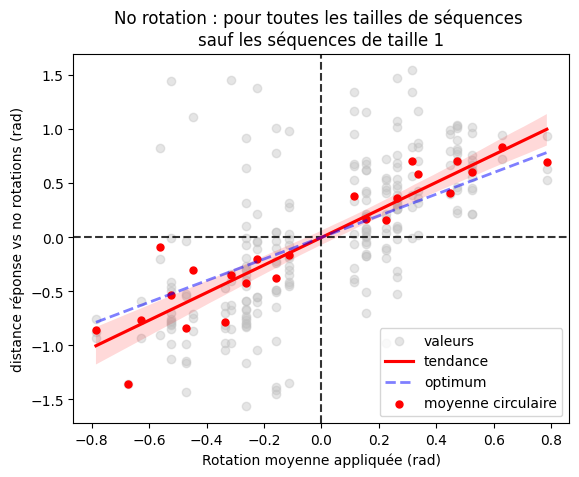

In [ ]:
df = df_radian[df_radian["length of sequence"]!=1]

x = (df.groupby("mean_rotation")["error_wo_rotation"].apply(np.mean).reset_index().sort_values("mean_rotation"))

plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
plt.axhline(0, color="black", linestyle="--", alpha = 0.8)   

borne = x["mean_rotation"]
sns.regplot(x="mean_rotation", y="error_wo_rotation", data=df, color = "silver", label = "valeurs", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "tendance"})
plt.plot(np.linspace(min(borne),max(borne),100),np.linspace(min(borne),max(borne),100),"--" , color = "blue",label= "optimum", alpha = 0.5, linewidth =2)
plt.scatter(x["mean_rotation"], x["error_wo_rotation"], color="red", s=25, label="moyenne circulaire")

plt.xlabel("Rotation moyenne appliquée (rad)")
plt.ylabel("distance réponse vs no rotations (rad)")
plt.title("No rotation : pour toutes les tailles de séquences \nsauf les séquences de taille 1")
plt.legend()
plt.show()

## Reaction time et confiance

### RT vs erreur

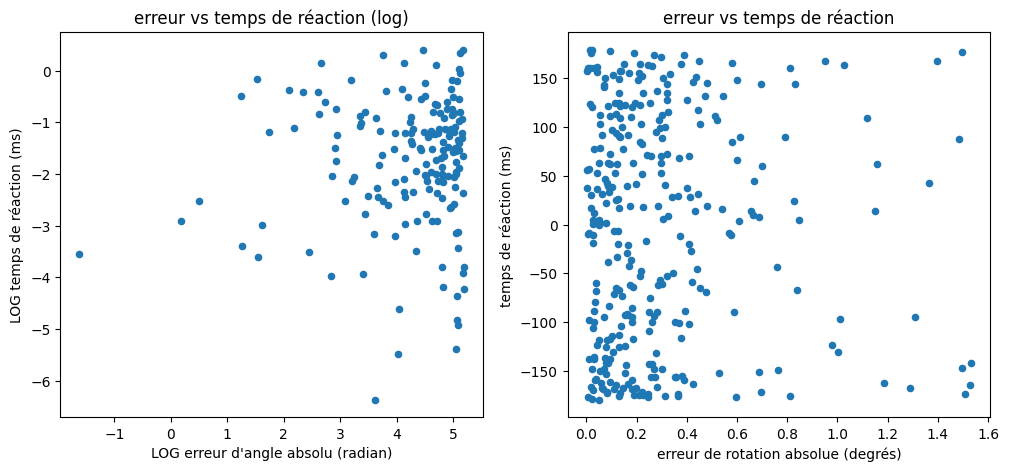

In [ ]:
plt.subplots(1,2, figsize=(12,5))

plt.subplot(1,2,1) 
plt.scatter(df_radian["trial_rt"].apply(np.log), np.abs(df_radian["error_to_target"]).apply(np.log), s=20)
plt.xlabel("LOG erreur d'angle absolu (radian)")
plt.ylabel("LOG temps de réaction (ms)")
plt.title("erreur vs temps de réaction (log)")

plt.subplot(1,2,2) 
plt.scatter(np.abs(df_radian["error_to_target"]), df_radian["trial_rt"], s=20)
plt.xlabel("erreur de rotation absolue (degrés)")
plt.ylabel("temps de réaction (ms)")
plt.title("erreur vs temps de réaction")
plt.show()

erreur vs le temps

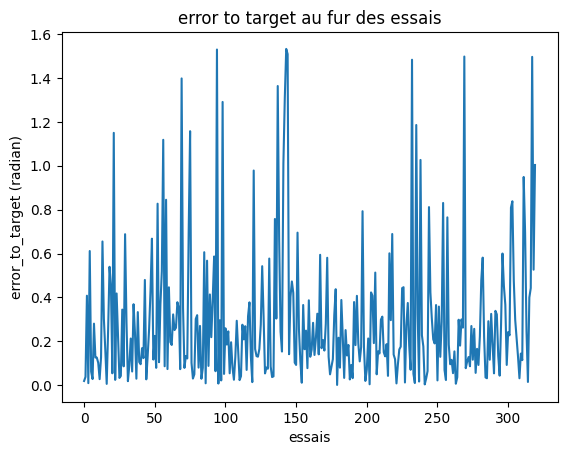

In [ ]:
plt.plot(np.abs(df_radian["error_to_target"]))
plt.xlabel("essais")
plt.ylabel("error_to_target (radian)")
plt.title("error to target au fur des essais")
plt.show()

### RT vs temps

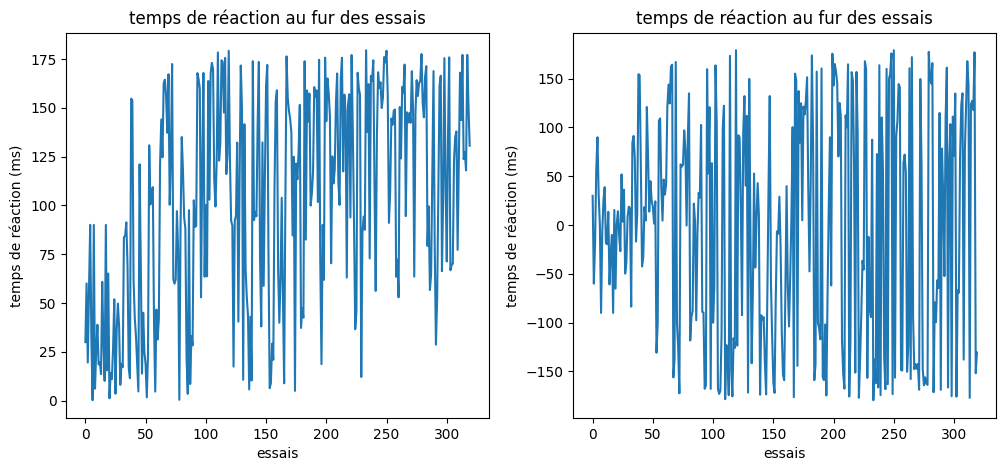

In [ ]:
plt.subplots(1,2, figsize=(12,5))

plt.subplot(1,2,1) 
plt.plot(np.abs(df_radian["trial_rt"]))
plt.xlabel("essais")
plt.ylabel("temps de réaction (ms)")
plt.title("temps de réaction au fur des essais")

mean_rt = df_radian["trial_rt"].mean()
std_rt = df_radian["trial_rt"].std()
upper_threshold = mean_rt + 2*std_rt

rt_filtered = df_radian["trial_rt"].copy()
rt_filtered[(rt_filtered > upper_threshold)] = np.nan

plt.subplot(1,2,2)
plt.plot(rt_filtered)
plt.xlabel("essais")
plt.ylabel("temps de réaction (ms)")
plt.title("temps de réaction au fur des essais")
plt.show()

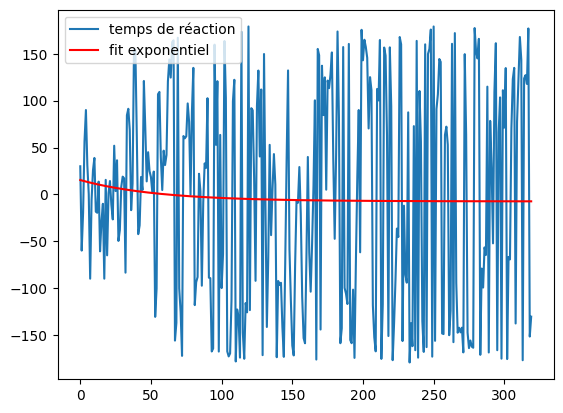

In [ ]:
from scipy.optimize import curve_fit
import numpy as np

y = rt_filtered.values.astype(float)
x = np.arange(len(y))

# enlever NaN et inf
mask = np.isfinite(y)
x_clean = x[mask]
y_clean = y[mask]

# modèle exponentiel
def exp_model(x, a, b, c):
    return a * np.exp(-b * x) + c

# fit
params, _ = curve_fit(
    exp_model,
    x_clean,
    y_clean,
    p0=[1000, 0.01, 2000],   # meilleurs guess
    maxfev=10000             # évite erreur convergence
)

a, b, c = params

# prédiction sur toute la courbe
y_fit_full = exp_model(x, a, b, c)

plt.plot(x, y, label="temps de réaction")
plt.plot(x, y_fit_full, "r", label="fit exponentiel")
plt.legend()
plt.show()

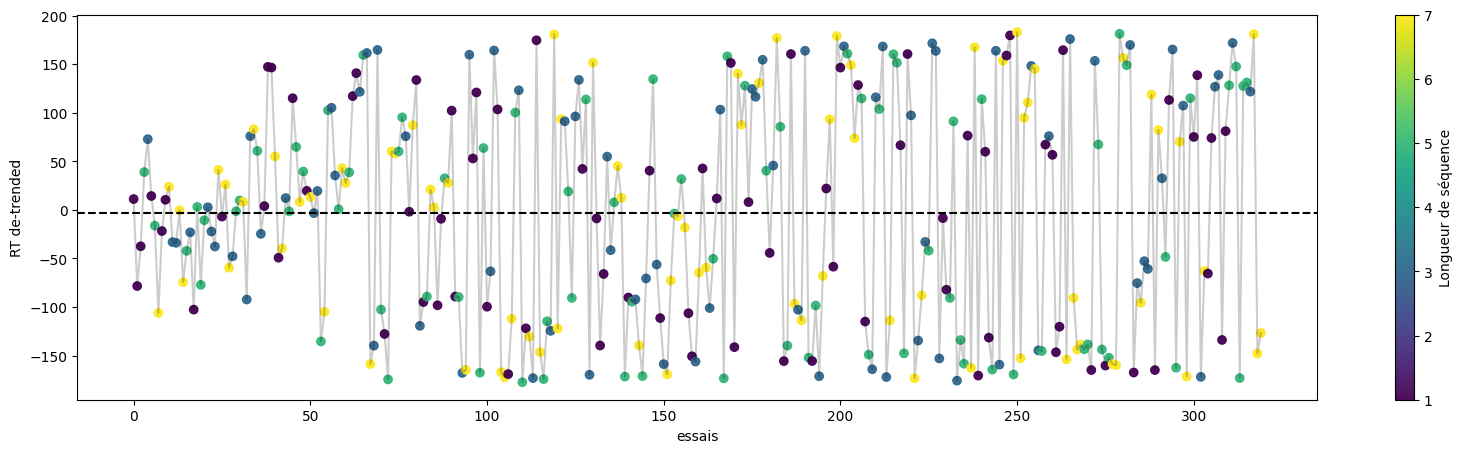

In [ ]:
seq = df_radian["length of sequence"].values

plt.figure(figsize=(20,5))

residuals = y - y_fit_full
residuals = y - y_fit_full + np.mean(y_fit_full)
plt.plot(x, residuals, color = "black", alpha = 0.2)
plt.scatter(x, residuals, c=seq, cmap="viridis", alpha=0.95)
plt.colorbar(label="Longueur de séquence")
plt.axhline(np.mean(residuals), color="black", linestyle="--")
plt.xlabel("essais")
plt.ylabel("RT de-trended")
plt.show()


### RT vs seq length

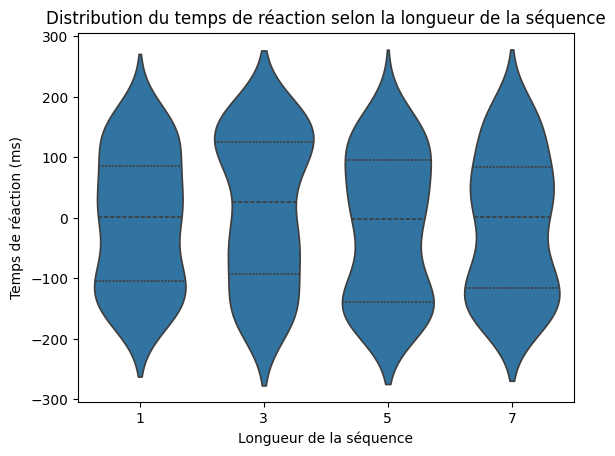

In [ ]:
sns.violinplot(x=seq, y=residuals, inner="quartile")

plt.xlabel("Longueur de la séquence")
plt.ylabel("Temps de réaction (ms)")
plt.title("Distribution du temps de réaction selon la longueur de la séquence")

plt.show()

### RT vs la confiance 

### RT vs score

In [ ]:
sns.violinplot(x="score", y=rt_filtered, data=df_radian, inner="quartile")

plt.xlabel("score")
plt.ylabel("Temps de réaction (ms)")
plt.title("Distribution du temps de réaction selon le score final")

plt.show()

ValueError: Could not interpret value `score` for `x`. An entry with this name does not appear in `data`.

## Analyses pour tous les participants

In [ ]:
def mean_par_sujet (column) : # donne une valeur par sujet
    df_participant = pd.DataFrame()
    for participant in range(104):
        df_participant[participant] = all_participants(dfs[participant])[column]
    # df_participant = df_participant.T    

    mean_matrix = df_participant.mean()
    return mean_matrix      

In [ ]:
def sd_par_sujet (column) : # donne une valeur par sujet
    df_participant = pd.DataFrame()
    for participant in range(104):
        df_participant[participant] = all_participants(dfs[participant])[column]
    # df_participant = df_participant.T    

    mean_matrix = df_participant.std()
    return mean_matrix      

### temps de réaction

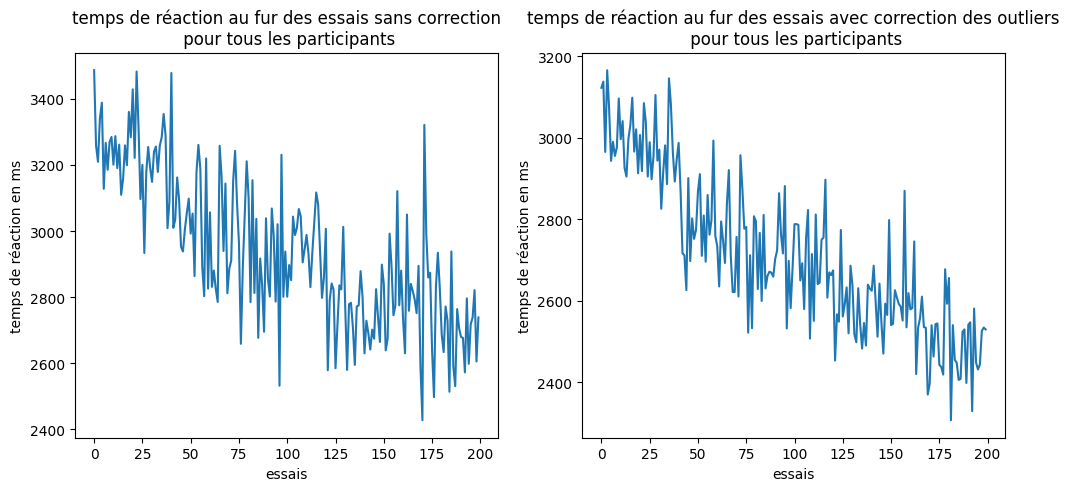

In [ ]:
all_rt = []
for participant in dfs : 
    df_part = all_participants(participant)
    rt = df_part["trial_rt"].values
    all_rt.append(rt)
    
rt_matrix = np.full((len(all_rt), max(len(rt) for rt in all_rt)), np.nan)

for i, rt in enumerate(all_rt):
    rt_matrix[i, :len(rt)] = rt 
mean_rt = np.nanmean(rt_matrix, axis=0)

plt.subplots(1,2, figsize=(12,5))

# plot n°1
plt.subplot(1,2,1) 
plt.plot(mean_rt)
plt.title("temps de réaction au fur des essais sans correction\n pour tous les participants")
plt.xlabel("essais")
plt.ylabel("temps de réaction en ms")


# plot n°2
# correction des grosses valeurs de RT

all_rt_2 = []
for participant in dfs : 
    df_part = all_participants(participant)
    rt = df_part["trial_rt"].values
    mean_rt2 = rt.mean()
    std_rt = rt.std()
    upper_threshold = mean_rt2 + 2*std_rt

    rt_clean = rt.copy()
    rt_clean[rt_clean > upper_threshold] = np.nan
        
    all_rt_2.append(rt_clean)
    
rt_matrix_2 = np.full((len(all_rt_2), max(len(rt) for rt in all_rt_2)), np.nan)

for i, rt in enumerate(all_rt_2):
    rt_matrix_2[i, :len(rt)] = rt 
mean_rt3 = np.nanmean(rt_matrix_2, axis=0)

plt.subplot(1,2,2) 
plt.plot(mean_rt3)
plt.title("temps de réaction au fur des essais avec correction des outliers\n pour tous les participants")
plt.xlabel("essais")
plt.ylabel("temps de réaction en ms")
# plt.savefig("/Users/elodiehusson/Desktop/Projet/Sanity check comportement code/temps de réaction de tous les sujets.pdf")
plt.show()

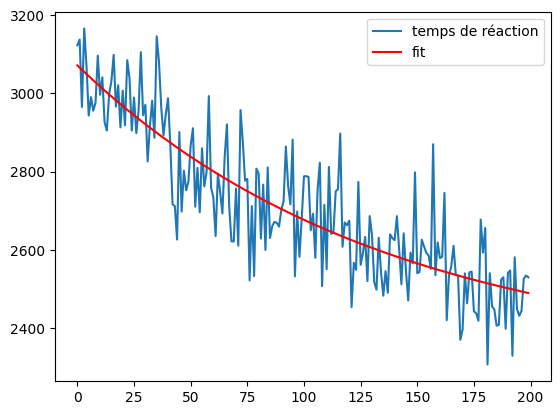

In [ ]:
from scipy.optimize import curve_fit

y = mean_rt3  
x = np.arange(len(y))

# modèle exponentiel
def exp_model(x, a, b, c):
    return a * np.exp(-b * x) + c

# fit
params, _ = curve_fit(exp_model, x, y, p0=[500, 0.01, 2500])
a, b, c = params

# courbe fit
y_fit = exp_model(x, a, b, c)

plt.plot(x, y, label="temps de réaction")
plt.plot(x, y_fit, "r", label="fit")
plt.legend()
# plt.savefig("/Users/elodiehusson/Desktop/Projet/Sanity check comportement code/temps de réaction fitté.pdf")
plt.show()


ici y'a un soucis sur l'axe, c'est assez étrange pq j'ai soustrait

je crois c'est bon si je commente la ligne là

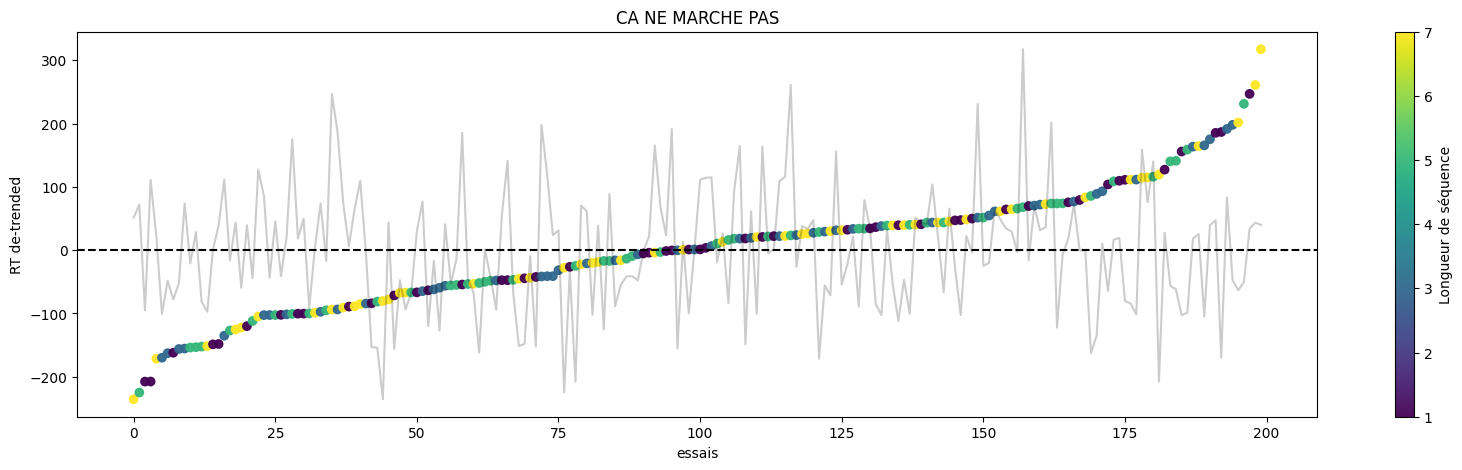

In [ ]:
seq = df_radian["length of sequence"].values

plt.figure(figsize=(20,5))

residuals = y - y_fit
# residuals = y - y_fit + np.mean(y_fit)
plt.plot(x, residuals, color = "black", alpha = 0.2)
plt.scatter(x, sorted(residuals), c=seq, cmap="viridis", alpha=0.95)
plt.colorbar(label="Longueur de séquence")
plt.axhline(np.mean(residuals), color="black", linestyle="--")
plt.xlabel("essais")
plt.ylabel("RT de-trended")
plt.title("CA NE MARCHE PAS")
plt.show()

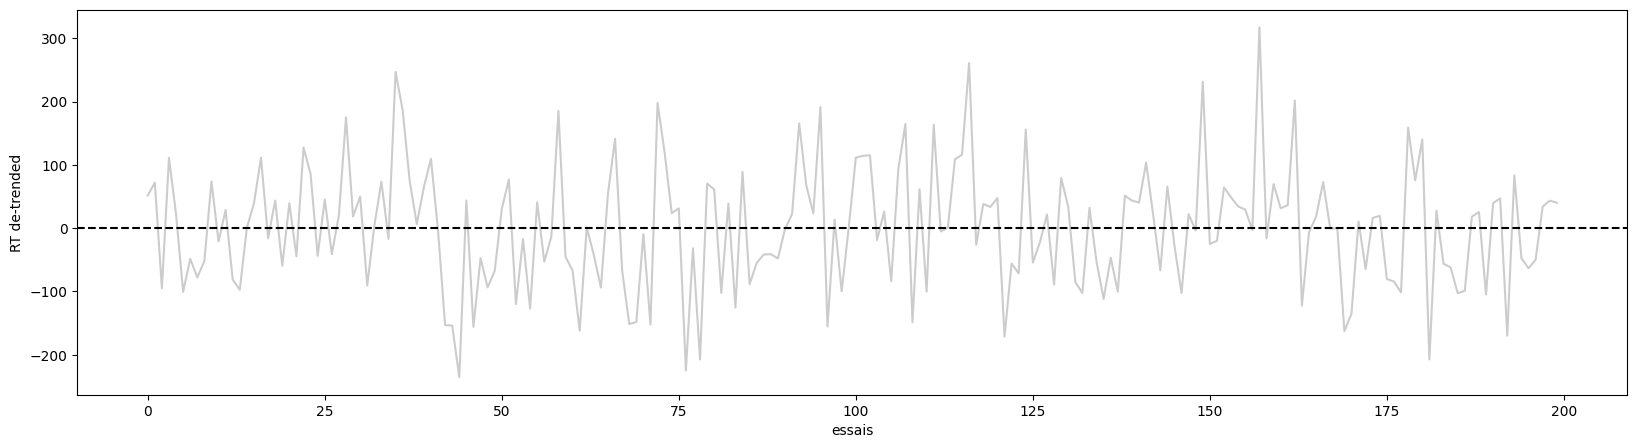

In [ ]:
seq = df_radian["length of sequence"].values

plt.figure(figsize=(20,5))

residuals = y - y_fit
# residuals = y - y_fit + np.mean(y_fit)
plt.plot(x, residuals, color = "black", alpha = 0.2)
# plt.scatter(x, residuals, c=seq, cmap="viridis", alpha=0.95)
# plt.colorbar(label="Longueur de séquence")
plt.axhline(np.mean(residuals), color="black", linestyle="--")
plt.xlabel("essais")
plt.ylabel("RT de-trended")
plt.show()


In [ ]:
print(len(x), len(residuals), len(seq))


200 200 200


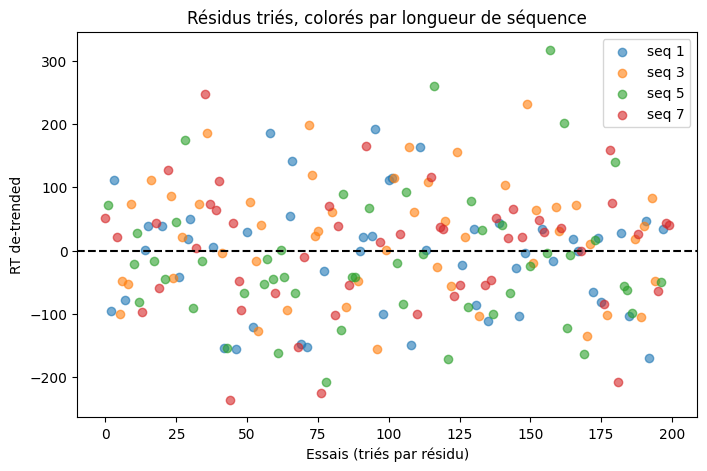

In [ ]:
seq = df_radian["length of sequence"].values

# indices de tri des résidus
idx = np.argsort(residuals)

# appliquer le même tri partout
residuals_sorted = residuals[idx]
x_sorted = x[idx]
seq_sorted = seq[idx]   # longueur de séquence

plt.figure(figsize=(8,5))

for s in [1, 3, 5, 7]:
    mask = seq_sorted == s
    plt.scatter(x_sorted[mask], sorted(residuals_sorted[mask]),
                label=f"seq {s}", alpha=0.6)

plt.axhline((np.mean(residuals_sorted)), color="black", linestyle="--")
plt.xlabel("Essais (triés par résidu)")
plt.ylabel("RT de-trended")
plt.title("Résidus triés, colorés par longueur de séquence")
plt.legend()
plt.show()


### distribution des angles tirés 

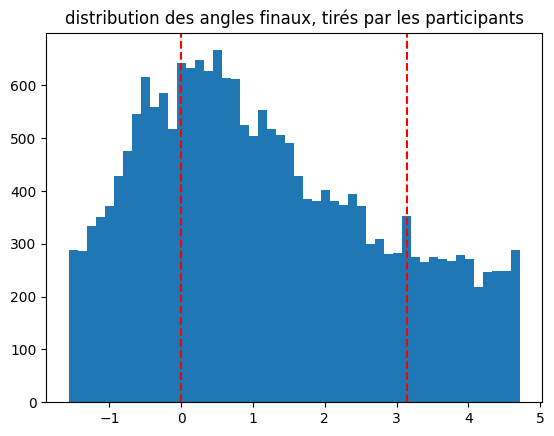

In [ ]:
all_final_angles = []

for participant in dfs:
    df_part = all_participants(participant)
    all_final_angles.extend(df_part["final_angle"].values)

all_final_angles = np.array(all_final_angles)


plt.hist(all_final_angles, bins=50)
plt.axvline(0, color='red', linestyle='--')
plt.axvline(np.pi, color='red', linestyle='--')
plt.title("distribution des angles finaux, tirés par les participants")
plt.show()

### distance/erreur à la target

/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_21804/2763086483.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_participant[participant] = all_participants(dfs[participant])[column]
/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_21804/2763086483.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_participant[participant] = all_participants(dfs[participant])[column]
/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_21804/2763086483.py:4: PerformanceWarning: DataFrame is highly fragmented

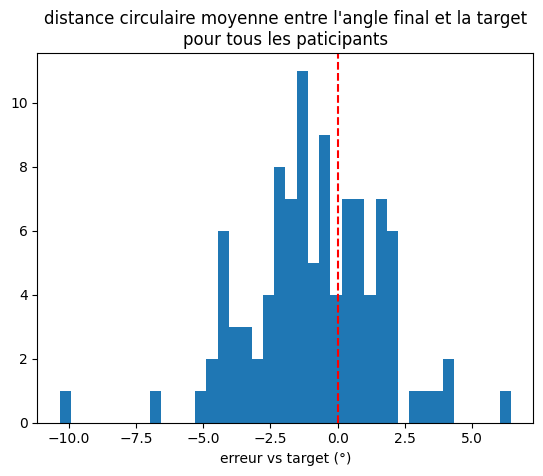

In [ ]:
mean_errors_per_participant = []

for participant in range(104):
    df_part = all_participants(dfs[participant])
    errors = df_part["error_to_target"].values
    mean_errors_per_participant.append(errors)

error_matrix = np.full((len(mean_errors_per_participant), max(len(errors) for errors in mean_errors_per_participant)), np.nan)

for i, errors in enumerate(mean_errors_per_participant):
    error_matrix[i, :len(errors)] = errors 
m_for_plot = np.nanmean(error_matrix, axis=0)

plt.hist(np.rad2deg(mean_par_sujet("error_to_target")), bins=40)
plt.axvline(0, color='red', linestyle='--') 
plt.xlabel("erreur vs target (°)")
plt.title("distance circulaire moyenne entre l'angle final et la target\npour tous les paticipants")
plt.show()

/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_21804/1559207486.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_participant[participant] = all_participants(dfs[participant])[column]
/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_21804/1559207486.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_participant[participant] = all_participants(dfs[participant])[column]
/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_21804/1559207486.py:4: PerformanceWarning: DataFrame is highly fragmented

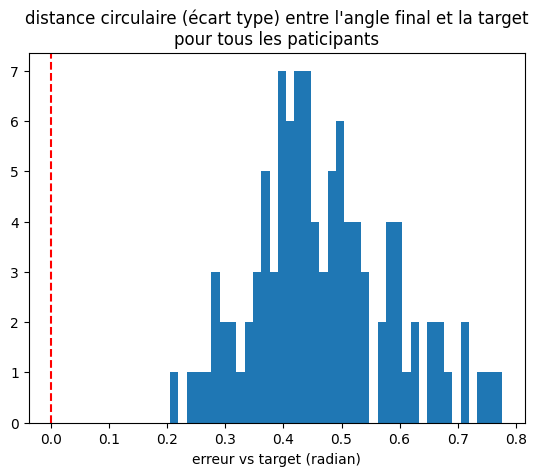

In [ ]:
mean_sd_per_participant = []

for participant in range(104):
    df_part = all_participants(dfs[participant])
    errors = df_part["error_to_target"].values
    mean_sd_per_participant.append(errors)

error_matrix = np.full((len(mean_sd_per_participant), max(len(errors) for errors in mean_sd_per_participant)), np.nan)

for i, errors in enumerate(mean_sd_per_participant):
    error_matrix[i, :len(errors)] = errors 
m_for_plot = np.nanmean(error_matrix, axis=0)

plt.hist(sd_par_sujet("error_to_target"), bins=40)
plt.axvline(0, color='red', linestyle='--') 
plt.xlabel("erreur vs target (radian)")
plt.title("distance circulaire (écart type) entre l'angle final et la target\npour tous les paticipants")
plt.show()
# pk l'écart type est pas à 0 ? parce que les participants font pas tous la même erreur, certains font des erreurs plus grandes que d'autres, et ça fait que la moyenne de l'écart type est pas nulle.

### distance/erreur aux no rotations

/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_21804/2763086483.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_participant[participant] = all_participants(dfs[participant])[column]
/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_21804/2763086483.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_participant[participant] = all_participants(dfs[participant])[column]
/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_21804/2763086483.py:4: PerformanceWarning: DataFrame is highly fragmented

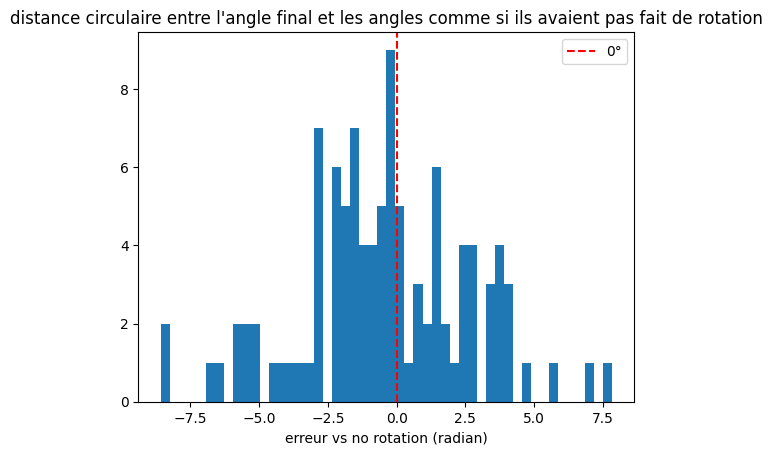

In [ ]:
plt.hist(np.rad2deg(mean_par_sujet("error_wo_rotation")), bins=50)
# plt.axvline(np.deg2rad(-45), color='darkred', linestyle='--', label="-45°") 
# plt.axvline(np.deg2rad(45), color='red', linestyle='--', label="+45°") 
plt.axvline(0, color='red', linestyle='--', label="0°") 

plt.xlabel("erreur vs no rotation (radian)")
plt.title("distance circulaire entre l'angle final et les angles comme si ils avaient pas fait de rotation")
plt.legend()
plt.show()

/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_21804/2763086483.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_participant[participant] = all_participants(dfs[participant])[column]
/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_21804/2763086483.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_participant[participant] = all_participants(dfs[participant])[column]
/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_21804/2763086483.py:4: PerformanceWarning: DataFrame is highly fragmented

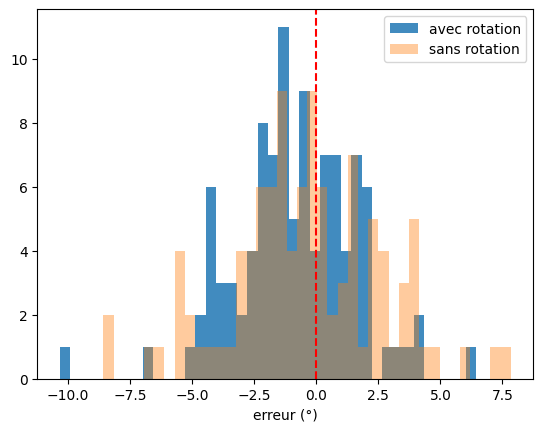

In [ ]:
plt.hist(np.rad2deg(mean_par_sujet("error_to_target")), bins=40, label="avec rotation", alpha = 0.85)
plt.hist(np.rad2deg(mean_par_sujet("error_wo_rotation")), bins=40, label="sans rotation", alpha = 0.4)
plt.axvline(0, color='red', linestyle='--')
plt.xlabel("erreur (°)")
plt.legend()
plt.show()

### rotations

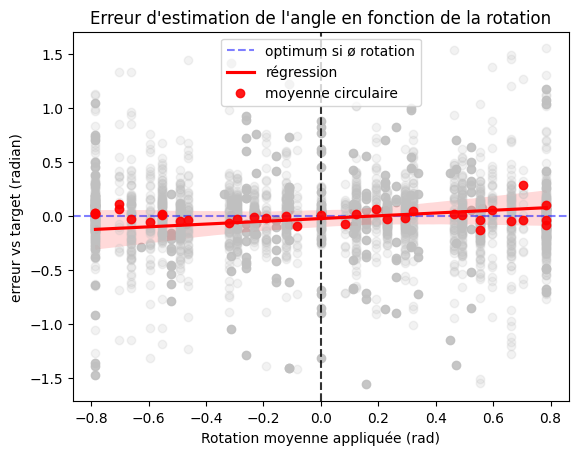

In [ ]:
participant_means = []

for participant in range(104):
    df_part = all_participants(dfs[participant])
    mean_by_rotation = df_part.groupby("mean_rotation")["error_to_target"].mean().reset_index()
    mean_by_rotation["participant"] = participant
    participant_means.append(mean_by_rotation)

df_means_all = pd.concat(participant_means, axis=0)
df_global_mean = df_means_all.groupby("mean_rotation")["error_to_target"].mean().reset_index()

for participant in df_means_all["participant"].unique():
    df_part = df_means_all[df_means_all["participant"] == participant]
    plt.plot(df_part["mean_rotation"], df_part["error_to_target"], 'o', color="silver", alpha=0.2)


plt.axhline(0, color="blue", linestyle="--" , label= "optimum si ø rotation", alpha = 0.5, linewidth =1.5) 
plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   

sns.regplot(x="mean_rotation", y="error_to_target", data=df_radian, color="silver", scatter_kws={'alpha':0.9}, line_kws={"color":"red", "label":"régression"})
plt.plot(df_global_mean["mean_rotation"], df_global_mean["error_to_target"], 'o', color="red", label="moyenne circulaire", linewidth = 1, alpha = 0.9)
# sns.regplot(x="mean_rotation", y="error_to_target", data=df_global_mean, color="white", scatter_kws={'alpha':0.9}, line_kws={"color":"orange", "label":"régression"})


plt.xlabel("Rotation moyenne appliquée (rad)")
plt.ylabel("erreur vs target (radian)")
plt.title("Erreur d'estimation de l'angle en fonction de la rotation")
plt.legend()
plt.show()

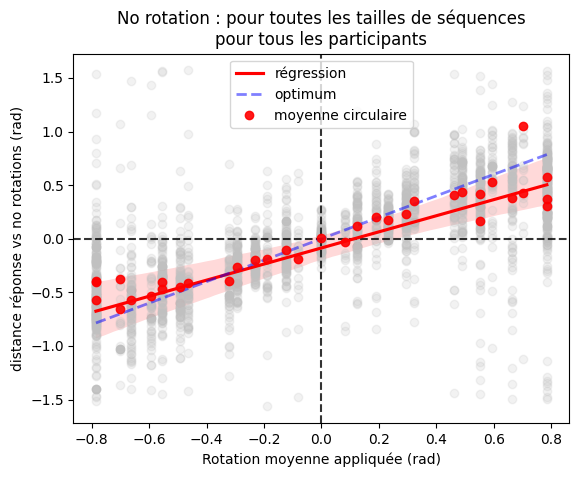

In [ ]:
participant_means = []

for participant in range(104):
    df_part = all_participants(dfs[participant])
    mean_by_rotation = df_part.groupby("mean_rotation")["error_wo_rotation"].mean().reset_index()
    mean_by_rotation["participant"] = participant
    participant_means.append(mean_by_rotation)

df_means_all = pd.concat(participant_means, axis=0)
df_global_mean = df_means_all.groupby("mean_rotation")["error_wo_rotation"].mean().reset_index()

for participant in df_means_all["participant"].unique():
    df_part = df_means_all[df_means_all["participant"] == participant]
    

    plt.plot(df_part["mean_rotation"], df_part["error_wo_rotation"], 'o', color="silver", alpha=0.2)


plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
plt.axhline(0, color="black", linestyle="--", alpha = 0.8)   

sns.regplot(x="mean_rotation", y="error_wo_rotation", data=df_part, color="silver", scatter_kws={'alpha':0.9}, line_kws={"color":"red", "label":"régression"})

borne = df_global_mean["mean_rotation"]
plt.plot(np.linspace(min(borne),max(borne),100),np.linspace(min(borne),max(borne),100),"--" , color = "blue",label= "optimum", alpha = 0.5, linewidth =2)
plt.plot(df_global_mean["mean_rotation"], df_global_mean["error_wo_rotation"], 'o', color="red", label="moyenne circulaire", linewidth = 1, alpha = 0.9)


plt.xlabel("Rotation moyenne appliquée (rad)")
plt.ylabel("distance réponse vs no rotations (rad)")
plt.title("No rotation : pour toutes les tailles de séquences\npour tous les participants")
plt.legend()
plt.show()




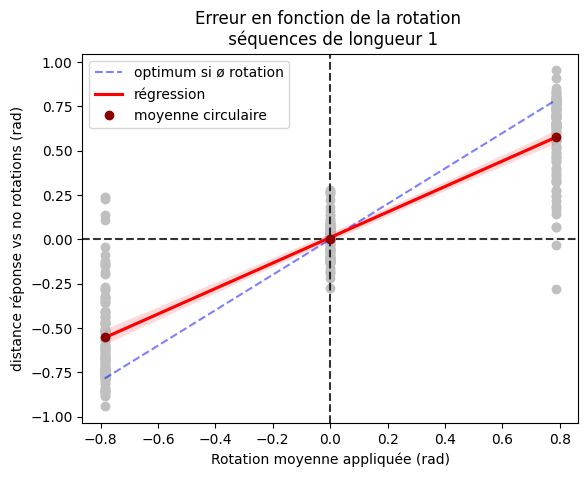

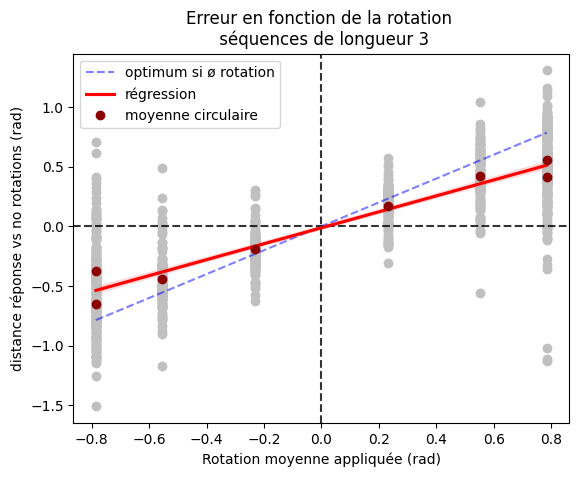

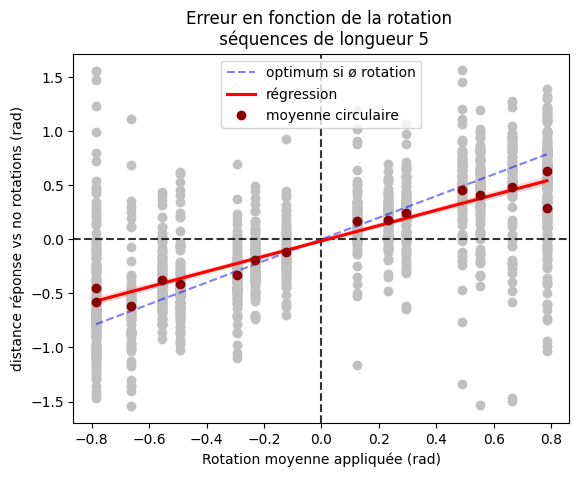

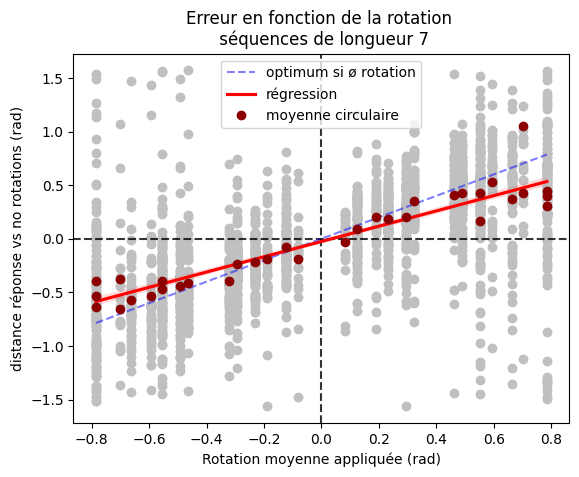

In [ ]:
for seqlen in [1,3,5,7] :
    plt.figure()
    # x = (df_radian[df_radian["length of sequence"]==seqlen].groupby("mean_rotation")["error_wo_rotation"].apply(np.mean).reset_index().sort_values("mean_rotation"))
    participant_means = []

    for participant in range(104):
        df_part = all_participants(dfs[participant])
        df_part = df_part[df_part["length of sequence"]==seqlen]
        mean_by_rotation = df_part.groupby("mean_rotation")["error_wo_rotation"].mean().reset_index()
        mean_by_rotation["participant"] = participant
        participant_means.append(mean_by_rotation)

    df_means_all = pd.concat(participant_means, axis=0)
    df_global_mean = df_means_all.groupby("mean_rotation")["error_wo_rotation"].mean().reset_index()

    for participant in df_means_all["participant"].unique():
        df_part = df_means_all[df_means_all["participant"] == participant]
        plt.plot(df_part["mean_rotation"], df_part["error_wo_rotation"], 'o', color="silver", alpha=0.2)


    plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
    plt.axhline(0, color="black", linestyle="--", alpha = 0.8)   


    borne = df_means_all["mean_rotation"]
    plt.plot(np.linspace(min(borne),max(borne),100),np.linspace(min(borne),max(borne),100),"--" , color = "blue",label= "optimum si ø rotation", alpha = 0.5, linewidth =1.5)
    sns.regplot(x="mean_rotation", y="error_wo_rotation", data=df_means_all, color="silver", scatter_kws={'alpha':1}, line_kws={"color":"red", "label":"régression"})
    plt.plot(df_global_mean["mean_rotation"], df_global_mean["error_wo_rotation"], 'o', color="darkred", label="moyenne circulaire")

 
    plt.xlabel("Rotation moyenne appliquée (rad)")
    plt.ylabel("distance réponse vs no rotations (rad)")
    plt.title(f"Erreur en fonction de la rotation \n séquences de longueur {seqlen}")
    plt.legend()
    plt.show()




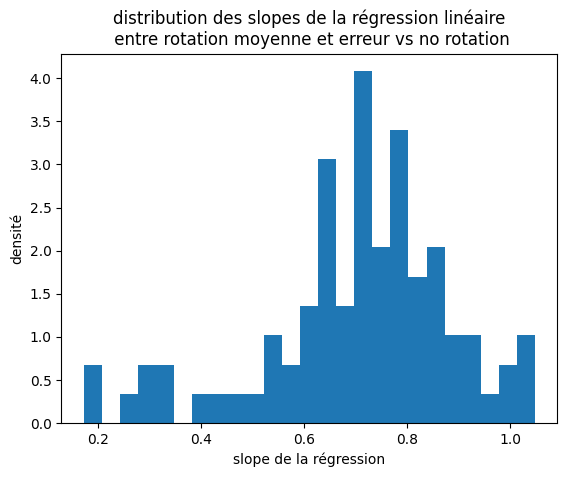

In [ ]:
result = []
for participant in range(104):
    df_part = all_participants(dfs[participant])
    df = df_part[df_part["length of sequence"]!=1]
    x = (df.groupby("mean_rotation")["error_wo_rotation"].apply(np.mean).reset_index().sort_values("mean_rotation"))
    result.append(linregress(df["mean_rotation"], df["error_wo_rotation"]).slope)
    
plt.hist(result, bins=25, density = True)
plt.title("distribution des slopes de la régression linéaire\n entre rotation moyenne et erreur vs no rotation")
plt.xlabel("slope de la régression")
plt.ylabel("densité")
# plt.savefig("/Users/elodiehusson/Desktop/Projet/Sanity check comportement code/distribution slopes.pdf")
plt.show()

### score et taille de séquence vs le temps de réaction

In [ ]:
mean_rt = {"1" : [], "3" : [], "5" : [], "7" : []}
for participant in range(104) :
    sequences = {"1" : [list(all_participants(dfs[participant])["rt_filtered"][all_participants(dfs[participant])["length of sequence"]==1])], 
                "3" : [list(all_participants(dfs[participant])["rt_filtered"][all_participants(dfs[participant])["length of sequence"]==3])], 
                "5" : [list(all_participants(dfs[participant])["rt_filtered"][all_participants(dfs[participant])["length of sequence"]==5])], 
                "7" : [list(all_participants(dfs[participant])["rt_filtered"][all_participants(dfs[participant])["length of sequence"]==7])]}

    for i in ["1", "3", "5", "7"] : 
        mean_rt[i].extend(sequences[i][0])
   
df_violin = pd.DataFrame({"rt_filtered": mean_rt["1"] + mean_rt["3"] + mean_rt["5"] + mean_rt["7"]})
df_violin["length of sequence"] = ["1"]*len(mean_rt["1"]) + ["3"]*len(mean_rt["3"]) + ["5"]*len(mean_rt["5"]) + ["7"]*len(mean_rt["7"])
df_violin


,rt_filtered,length of sequence
0,2217.0,1
1,3330.0,1
2,2276.0,1
3,3272.0,1
4,1970.0,1
...,...,...
20795,4927.0,7
20796,3941.0,7
20797,2461.0,7
20798,2109.0,7


In [ ]:
mean_rt = {"1" : [], "3" : [], "5" : [], "7" : []}
for participant in range(104) :
    sequences = {"1" : [list(all_participants(dfs[participant])["rt_filtered"][all_participants(dfs[participant])["length of sequence"]==1])], 
                "3" : [list(all_participants(dfs[participant])["rt_filtered"][all_participants(dfs[participant])["length of sequence"]==3])], 
                "5" : [list(all_participants(dfs[participant])["rt_filtered"][all_participants(dfs[participant])["length of sequence"]==5])], 
                "7" : [list(all_participants(dfs[participant])["rt_filtered"][all_participants(dfs[participant])["length of sequence"]==7])]}

    for i in ["1", "3", "5", "7"] : 
        mean_rt[i].extend(sequences[i][0])
   
df_violin = pd.DataFrame({"rt_filtered": mean_rt["1"] + mean_rt["3"] + mean_rt["5"] + mean_rt["7"]})
df_violin["length of sequence"] = ["1"]*len(mean_rt["1"]) + ["3"]*len(mean_rt["3"]) + ["5"]*len(mean_rt["5"]) + ["7"]*len(mean_rt["7"])
df_violin


,rt_filtered,length of sequence
0,2217.0,1
1,3330.0,1
2,2276.0,1
3,3272.0,1
4,1970.0,1
...,...,...
20795,4927.0,7
20796,3941.0,7
20797,2461.0,7
20798,2109.0,7


ValueError: x and y must have same first dimension, but have shapes (25, 2) and (200,)

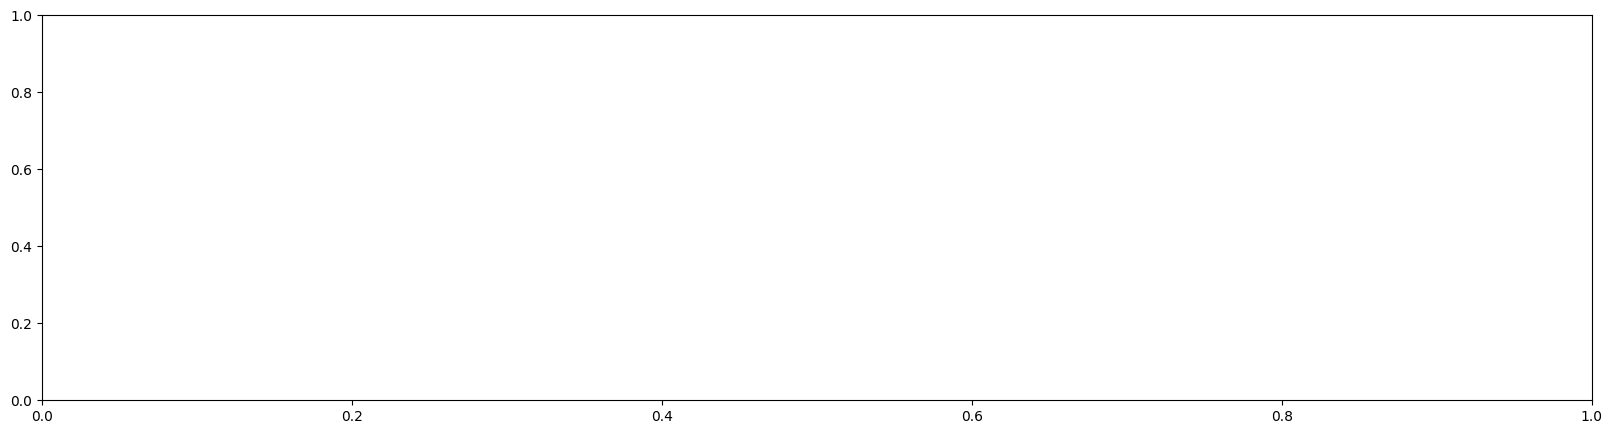

In [ ]:
seq = df_radian["length of sequence"].values

plt.figure(figsize=(20,5))

residuals = y - y_fit
residuals = y - y_fit + np.mean(y_fit)
plt.plot(x, residuals, color = "black", alpha = 0.2)
plt.scatter(x, residuals, c=seq, cmap="viridis", alpha=0.95)
plt.colorbar(label="Longueur de séquence")
plt.axhline(np.mean(residuals), color="black", linestyle="--")
plt.xlabel("essais")
plt.ylabel("RT de-trended")
plt.show()


In [ ]:
sns.violinplot(x="length of sequence", y=residuals, data=df_violin, inner="quartile")

plt.xlabel("Longueur de la séquence")
plt.ylabel("Temps de réaction (ms)")
plt.title("Distribution du temps de réaction selon la longueur de la séquence")

plt.show()

ValueError: Length of ndarray vectors must match length of `data` when both are used, but `data` has length 20800 and the vector passed to `y` has length 200.

In [ ]:
mean_score = {"0" : [], "2" : [], "4" : [], "6" : [], "8" : [], "10" : []}
for participant in range(104) :
    scores = {"0" : [list(all_participants(dfs[participant])["rt_filtered"][all_participants(dfs[participant])["score"]==0])], 
                "2" : [list(all_participants(dfs[participant])["rt_filtered"][all_participants(dfs[participant])["score"]==2])], 
                "4" : [list(all_participants(dfs[participant])["rt_filtered"][all_participants(dfs[participant])["score"]==4])], 
                "6" : [list(all_participants(dfs[participant])["rt_filtered"][all_participants(dfs[participant])["score"]==6])],
                "8" : [list(all_participants(dfs[participant])["rt_filtered"][all_participants(dfs[participant])["score"]==8])],
                "10" : [list(all_participants(dfs[participant])["rt_filtered"][all_participants(dfs[participant])["score"]==10])]}
    

    for i in ["0", "2", "4", "6", "8", "10"] : 
        mean_score[i].extend(scores[i][0])

df_violin_score = pd.DataFrame({"score_filtered": mean_score["0"] + mean_score["2"] + mean_score["4"] + mean_score["6"] + mean_score["8"] + mean_score["10"]})
df_violin_score["score"] = ["0"]*len(mean_score["0"]) + ["2"]*len(mean_score["2"]) + ["4"]*len(mean_score["4"]) + ["6"]*len(mean_score["6"]) + ["8"]*len(mean_score["8"]) + ["10"]*len(mean_score["10"])
df_violin_score


,score_filtered,score
0,2537.0,0
1,1963.0,0
2,3272.0,0
3,2106.0,0
4,1970.0,0
...,...,...
20795,2359.0,10
20796,3188.0,10
20797,4564.0,10
20798,3130.0,10


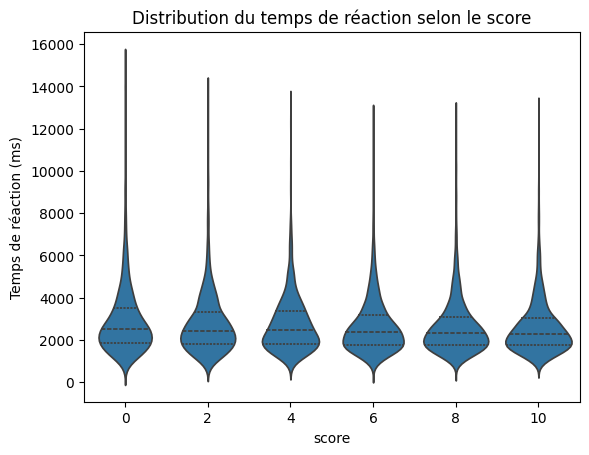

In [ ]:

sns.violinplot(x="sc ore", y=residuals, data=df_violin_score, inner="quartile")

plt.xlabel("score")
plt.ylabel("Temps de réaction (ms)")
plt.title("Distribution du temps de réaction selon le score")

plt.show()

In [ ]:
from scipy.optimize import curve_fit
import numpy as np

def exp_model(x, a, b, c):
    return a * np.exp(-b * x) + c

def fit_participant(df_part):

    df_part = df_part.copy()
    
    mask = np.isfinite(df_part["rt_filtered"])
    df_part = df_part[mask].copy()
    
    if len(df_part) < 10:
        return None   # pas assez de données
    
    x = np.arange(len(df_part))
    y = df_part["rt_filtered"].values
    
    try:
        params, _ = curve_fit(
            exp_model,
            x,
            y,
            p0=[1000, 0.01, 2000],
            maxfev=10000
        )
    except:
        return None
    
    a, b, c = params
    y_fit = exp_model(x, a, b, c)
    
    df_part["residuals"] = y - y_fit
    df_part["a"] = a
    df_part["b"] = b
    df_part["c"] = c
    
    return df_part


In [ ]:
df_all = []

for pid, df_part in df.groupby("participant"):
    fitted = fit_participant(df_part)
    if fitted is not None:
        df_all.append(fitted)

df_residuals = pd.concat(df_all, ignore_index=True)

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

sns.violinplot(
    x="score",
    y="residuals",
    data=df_residuals,
    inner="quartile"
)

plt.axhline(0, color="black", linestyle="--")
plt.title("Résidus intra-participant selon le score")
plt.show()


KeyError: 'participant'